In [1]:
# ==============================================================================
#  SETUP (run first)
# ==============================================================================
# ══════════════════════════════════════════════════════════════════════════════
#  SETUP — build consensus_df from github-spread/Annotation_PennEPIID.csv
#    (no raw annotator xlsx merging; uses the public CSV that already contains
#     Group_1~5 / Majority_Group / Agreed_Annotators)
# ══════════════════════════════════════════════════════════════════════════════
import pandas as pd
import numpy as np
import re
import ast
from collections import Counter

ANNOTATION_CSV = '../dataset/Annotation_PennEPIID.csv'

consensus_df = pd.read_csv(ANNOTATION_CSV)
consensus_df = consensus_df.rename(columns={'PennEPI': 'Patient_id'})
consensus_df['ieeg_file_name'] = consensus_df['edf_file_name']   # alias for compatibility with older code (used only in log output)

# Group_1~5 / Majority_Group / Agreed_Annotators in the github-spread CSV are a snapshot
# computed from the channel text at export time, so later edits to Your_onset_channel_i
# (e.g., restoring midline, removing invalid electrode pairs) are not reflected automatically.
# -> As in the original live pipeline, Group_i is recomputed every time from the
#    channel/time text (the CSV's existing Group_i/Majority_Group/Agreed_Annotators are discarded).
def get_laterality(channel_str):
    if channel_str is None:
        return None
    if isinstance(channel_str, list):
        if len(channel_str) == 0:
            return None
        val_lower = ",".join(map(str, channel_str)).lower()
    else:
        if pd.isna(channel_str) or str(channel_str).lower() in ['n/a', 'none', '', 'nan']:
            return None
        val_lower = str(channel_str).lower()
    if 'diffuse' in val_lower:
        return 'generalized/bilateral'
    nums = re.findall(r'\d+', val_lower)
    if not nums:
        return None
    nums = [int(n) for n in nums]
    has_odd = any(n % 2 != 0 for n in nums)
    has_even = any(n % 2 == 0 for n in nums)
    if has_odd and has_even:
        return 'generalized/bilateral'
    return 'left' if has_odd else 'right'

def assign_group(row, idx):
    onset_time_val = row.get(f'Your_onset_time (s)_{idx}')
    if pd.isna(onset_time_val):
        return None
    val_str = str(onset_time_val).lower().strip()
    if val_str in ['no seizure', 'no_seizure', 'n/a', 'none']:
        return 'no seizure'
    onset_chan_val = row.get(f'Your_onset_channel_{idx}')
    spread_time_val = row.get(f'Your_contralateral_spread_time (s)_{idx}')
    onset_lat = get_laterality(onset_chan_val)
    is_no_spread = pd.isna(spread_time_val) or str(spread_time_val).lower().strip() in ['n/a', 'none', '', 'nan', 'same']
    if onset_lat == 'generalized/bilateral':
        return 'generalized/bilateral'
    if is_no_spread:
        if onset_lat == 'left':
            return 'only left'
        if onset_lat == 'right':
            return 'only right'
        return 'other'
    if onset_lat == 'left':
        return 'left to spread'
    if onset_lat == 'right':
        return 'right to spread'
    return 'other'

def get_majority_info_flexible(row):
    groups = [row[f'Group_{i}'] for i in range(1, 6) if row[f'Group_{i}'] is not None]
    if not groups:
        return pd.Series([None, []])
    counts = Counter(groups)
    majority_group, count = counts.most_common(1)[0]
    if count >= 2:
        agreed_annotators = [i for i in range(1, 6) if row[f'Group_{i}'] == majority_group]
        return pd.Series([majority_group, agreed_annotators])
    return pd.Series([None, []])

for _i in range(1, 6):
    consensus_df[f'Group_{_i}'] = consensus_df.apply(lambda row: assign_group(row, _i), axis=1)
consensus_df[['Majority_Group', 'Agreed_Annotators']] = consensus_df.apply(get_majority_info_flexible, axis=1)
# Note: the original notebook merges 'other' (laterality undeterminable, e.g., midline-only response)
# into 'generalized/bilateral', which would miscount responses with undeterminable laterality
# as Bilateral. Here 'other' is kept as is
# (it maps to none of Left/Right/Bilateral in _map_to_group etc., so it is automatically
#  excluded from the laterality analyses).

n_resp = consensus_df[[f'Group_{i}' for i in range(1, 6)]].notna().sum(axis=1)
print(f"[consensus_df] loaded github-spread CSV + recomputed Group: {len(consensus_df)} seizures "
      f"(number-of-raters distribution: {n_resp.value_counts().to_dict()})")


# ══════════════════════════════════════════════════════════════════════════════
#  Common seizure inclusion criteria for onset analyses (laterality / channel / onset-time MAD)
#  (same definition as cell 1 of the original notebook)
# ══════════════════════════════════════════════════════════════════════════════
_ONSET_PAIR_RE = re.compile(r'[A-Za-z]{1,4}\d{0,2}\s*-\s*[A-Za-z]{1,4}\d{0,2}')

def onset_is_no_seizure(val):
    """Whether the onset_time field is 'no seizure' / 'no_seizure'."""
    return "no seizure" in str(val).strip().lower().replace("_", " ")

def onset_has_channel_pair(val):
    """True if the onset annotation has at least one electrode pair like 'FP1-F9', or is 'diffuse'.
    Midline-only responses such as Fz/Cz/Pz (e.g., 'Cz-Pz') have no digits, so laterality
    cannot be determined; they are skipped -> treated as invalid if there are no digits."""
    if val is None:
        return False
    if isinstance(val, (list, tuple, set)):
        return len(val) > 0
    s = str(val).strip()
    if s == "" or s.lower() in ("nan", "n/a", "none"):
        return False
    if onset_is_no_seizure(s):
        return False
    if "diffuse" in s.lower():
        return True
    if not any(ch.isdigit() for ch in s):
        return False   # midline-only response (Fz/Cz/Pz only) -> skip (invalid)
    return bool(_ONSET_PAIR_RE.search(s))

def onset_seizure_inclusion(row):
    """
    Seizure inclusion criteria shared by all onset analyses.
      present_ids   : annotators with Group_i filled (= annotated). This dataset has 3 per seizure.
      no_seizure_ids: present annotators whose onset_time is 'no seizure'
      valid_ids     : present annotators who are not no-seizure and have >=1 pair in the onset channel

    Rules:
      1) exclude if present is not exactly 3  (nan = did not annotate)
      2) exclude if 'no seizure' from 2 or more annotators
      3) exclude if fewer than 2 valid_ids (with channel pairs)  (pairwise not computable)
    """
    present_ids = []
    for i in range(1, 6):
        g = row.get(f'Group_{i}', None)
        if g is None:
            continue
        try:
            if pd.isna(g):
                continue
        except (TypeError, ValueError):
            pass
        if str(g).strip() == "":
            continue
        present_ids.append(i)

    no_seizure_ids = [i for i in present_ids
                      if onset_is_no_seizure(row.get(f'Your_onset_time (s)_{i}', ""))]
    valid_ids = [i for i in present_ids
                 if i not in no_seizure_ids
                 and onset_has_channel_pair(row.get(f'Your_onset_channel_{i}', None))]

    if len(present_ids) != 3:
        inc, reason = False, f'present!=3({len(present_ids)})'
    elif len(no_seizure_ids) >= 2:
        inc, reason = False, 'no_seizure>=2'
    elif len(valid_ids) < 2:
        inc, reason = False, f'valid_channel_raters<2({len(valid_ids)})'
    else:
        inc, reason = True, 'ok'

    return {'included': inc, 'present_ids': present_ids,
            'no_seizure_ids': no_seizure_ids, 'valid_ids': valid_ids, 'reason': reason}

def ensure_onset_inclusion_cols(df):
    """Return a copy with onset_included / onset_valid_ids added if missing (unchanged if present)."""
    if 'onset_included' in df.columns and 'onset_valid_ids' in df.columns:
        return df
    df = df.copy()
    _oi = df.apply(onset_seizure_inclusion, axis=1)
    df['onset_included']       = _oi.apply(lambda d: d['included'])
    df['onset_valid_ids']      = _oi.apply(lambda d: d['valid_ids'])
    df['onset_no_seizure_ids'] = _oi.apply(lambda d: d['no_seizure_ids'])
    df['onset_incl_reason']    = _oi.apply(lambda d: d['reason'])
    return df

consensus_df = ensure_onset_inclusion_cols(consensus_df)
print(f"[onset common inclusion set] included {int(consensus_df['onset_included'].sum())} / {len(consensus_df)}")
print("  by exclusion reason:")
print(consensus_df.loc[~consensus_df['onset_included'], 'onset_incl_reason']
      .value_counts().to_string())

# ══════════════════════════════════════════════════════════════════════════════
#  Onset laterality mapping helper shared by several cells (first defined in the original notebook's
#  "(1) Percent Agreement" cell and reused by later cells such as Fleiss/Brennan-Prediger)
# ══════════════════════════════════════════════════════════════════════════════
_LEFT, _RIGHT, _BILAT = {'only left', 'left to spread'}, {'only right', 'right to spread'}, {'generalized/bilateral'}
def _map_to_group(val):
    if val in _LEFT:  return 'Left'
    if val in _RIGHT: return 'Right'
    if val in _BILAT: return 'Bilateral'
    return None

RATER_IDS = [1, 2, 3, 4, 5]


# ══════════════════════════════════════════════════════════════════════════════
#  Contralateral spread Yes/No helpers (used by the Fleiss' kappa / Gwet's AC1 cells)
#  (originally in the pairwise agreement table cell; moved here when that cell moved to supplement_figure.ipynb)
# ══════════════════════════════════════════════════════════════════════════════
def get_spread_bilateral_yes(val):
    """'X to spread' -> Yes, 'only X' -> No, 'generalized/bilateral' -> Yes (already bilateral)."""
    if val in ('left to spread', 'right to spread'): return 'Yes'
    if val in ('only left', 'only right'):           return 'No'
    if val == 'generalized/bilateral':               return 'Yes'
    return None


def build_spread_records_all_included(df):
    """
    Uses all seizures in the common inclusion set (onset_included), regardless of whether onset
    laterality agrees across raters. For each seizure, spread Yes/No is taken from each
    onset_valid_ids rater's own label (bilateral -> Yes); included if >=2 valid responses.
    """
    df = ensure_onset_inclusion_cols(df)
    records, n_total = [], 0
    for index, row in df.iterrows():
        if not row['onset_included']:
            continue
        n_total += 1
        vals = [get_spread_bilateral_yes(row.get(f'Group_{i}')) for i in row['onset_valid_ids']]
        vals = [v for v in vals if v is not None]
        if len(vals) < 2:
            continue
        records.append({
            'seizure_id':  index,
            'patient_id':  row['Patient_id'],
            'spread_vals': vals,
        })
    print(f"[whole common inclusion set, regardless of onset agreement, bilateral->Yes] using {len(records)} of {n_total} seizures")
    return pd.DataFrame(records)


[consensus_df] loaded github-spread CSV + recomputed Group: 79 seizures (number-of-raters distribution: {3: 79})
[onset common inclusion set] included 78 / 79
  by exclusion reason:
onset_incl_reason
no_seizure>=2    1


Onset laterality: 78 seizures, 48 patients


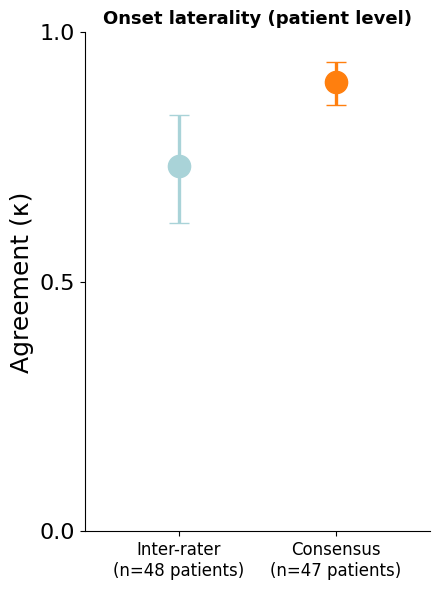

[Onset laterality, patient level]
  Inter-rater  n= 48 patients  κ = 0.73 [0.62, 0.83]
  Consensus    n= 47 patients  κ = 0.90 [0.86, 0.94]
[whole common inclusion set, regardless of onset agreement, bilateral->Yes] using 78 of 78 seizures
Contralateral spread: 78 seizures, 48 patients


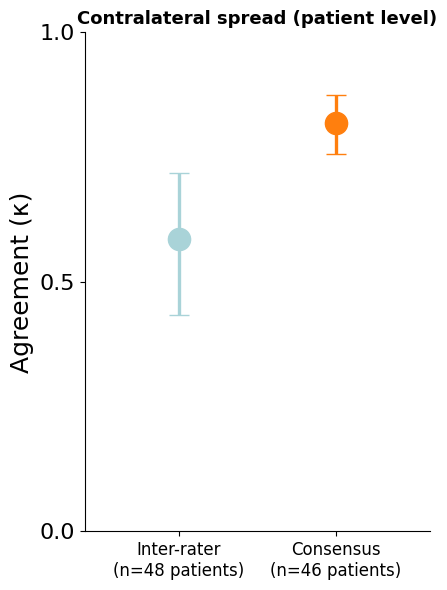

[Contralateral spread, patient level]
  Inter-rater  n= 48 patients  κ = 0.59 [0.43, 0.72]
  Consensus    n= 46 patients  κ = 0.82 [0.76, 0.88]


In [2]:
# ==============================================================================
#  Supplementary Figure 1 — Gwet's AC1, patient level (onset laterality / contralateral spread)
# ==============================================================================
# ══════════════════════════════════════════════════════════════════════════════
#  Gwet's AC1 — Overall, PATIENT LEVEL
#    - per-seizure AC1 is computed exactly as in the Overall cell of main_figure.ipynb
#      (po = pairwise / vs-majority, pe = global pe_AC1 over the whole group = (1/(q-1)) Σ p_c(1-p_c))
#    - difference: 1 patient = 1 point. AC1 is averaged over each patient's seizures, and
#      the mean of the patient means is the point estimate (main pools all seizures instead)
#    - 95% CI: 1,000 bootstrap resamples of the patient means (resampling patients)
#    - Inter-rater (light blue) / Consensus (orange, No-consensus excluded) in one panel
# ══════════════════════════════════════════════════════════════════════════════
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations

COL_INTER   = "#A9D3D8"   # light blue
COL_CONSENS = "#ff7f0e"   # orange


def _po_overall(vals_list):
    out = []
    for vals in vals_list:
        pairs = list(combinations(vals, 2))
        out.append(np.nan if not pairs else np.mean([1.0 if a == b else 0.0 for a, b in pairs]))
    return np.array(out, dtype=float)


def _con_po_overall(vals_list, majority_list):
    out = []
    for vals, maj in zip(vals_list, majority_list):
        out.append(np.nan if (maj == 'No consensus' or maj is None)
                    else np.mean([1.0 if v == maj else 0.0 for v in vals]))
    return np.array(out, dtype=float)


def _ac1_overall(vals_list, majority_list, categories):
    all_vals = [v for vals in vals_list for v in vals]
    p = {c: all_vals.count(c) / len(all_vals) for c in categories}
    q = len(categories)
    pe = (1 / (q - 1)) * sum(p[c] * (1 - p[c]) for c in categories)
    ir_ac1  = (_po_overall(vals_list) - pe) / (1 - pe)
    con_ac1 = (_con_po_overall(vals_list, majority_list) - pe) / (1 - pe)
    return ir_ac1, con_ac1



def _patient_means(values, patient_ids):
    """Seizure-level values -> per-patient means (NaN seizures excluded). Returns (patient ids, patient means)."""
    values = np.asarray(values, float)
    patient_ids = np.asarray(patient_ids)
    valid = ~np.isnan(values)
    s = pd.Series(values[valid]).groupby(patient_ids[valid]).mean()
    return s.index.to_numpy(), s.to_numpy()


def _patient_boot_ci(values, patient_ids, n_bootstrap=1000, seed=42):
    """Mean of patient means + patient-level bootstrap 95% CI. Returns (point, lo, hi, n_patients)."""
    _, pm = _patient_means(values, patient_ids)
    if len(pm) == 0:
        return (np.nan, np.nan, np.nan, 0)
    rng = np.random.default_rng(seed)
    boot = [np.mean(rng.choice(pm, size=len(pm), replace=True)) for _ in range(n_bootstrap)]
    return float(np.mean(pm)), float(np.percentile(boot, 2.5)), float(np.percentile(boot, 97.5)), len(pm)


def _plot_ac1_patient_single_panel(ir_ac1, con_ac1, pid, title):
    ir_m, ir_lo, ir_hi, n_ir     = _patient_boot_ci(ir_ac1, pid)
    con_m, con_lo, con_hi, n_con = _patient_boot_ci(con_ac1, pid)

    fig, ax = plt.subplots(figsize=(4.5, 6))
    ax.errorbar(0, ir_m, yerr=[[ir_m - ir_lo], [ir_hi - ir_m]], fmt='o', color=COL_INTER,
               markersize=16, capsize=7, linewidth=2.4, zorder=3)
    ax.errorbar(1, con_m, yerr=[[con_m - con_lo], [con_hi - con_m]], fmt='o', color=COL_CONSENS,
               markersize=16, capsize=7, linewidth=2.4, zorder=3)
    ax.set_xticks([0, 1])
    ax.set_xticklabels([f"Inter-rater\n(n={n_ir} patients)", f"Consensus\n(n={n_con} patients)"], fontsize=12)
    ax.set_xlim(-0.6, 1.6)
    ax.set_ylim(0.0, 1.0)
    ax.set_yticks([0.0, 0.5, 1.0])
    ax.set_ylabel("Agreement (κ)", fontsize=18)
    ax.set_title(f"{title} (patient level)", fontsize=13, fontweight='bold')
    ax.tick_params(axis='y', labelsize=16)
    ax.spines[['top', 'right']].set_visible(False)
    plt.tight_layout()
    plt.show()

    print(f"[{title}, patient level]")
    print(f"  Inter-rater  n={n_ir:3d} patients  κ = {ir_m:.2f} [{ir_lo:.2f}, {ir_hi:.2f}]")
    print(f"  Consensus    n={n_con:3d} patients  κ = {con_m:.2f} [{con_lo:.2f}, {con_hi:.2f}]")


def _build_laterality_lists(df):
    _df = ensure_onset_inclusion_cols(df)
    vals_list, majority_list, pid_list = [], [], []
    for _, row in _df.iterrows():
        if not row['onset_included']:
            continue
        vals = [_map_to_group(row.get(f'Group_{i}')) for i in row['onset_valid_ids']]
        vals = [v for v in vals if v in ('Left', 'Right', 'Bilateral')]
        if len(vals) < 2:
            continue
        mode = pd.Series(vals).mode()
        maj = mode[0] if (len(mode) == 1 and vals.count(mode[0]) >= 2) else 'No consensus'
        vals_list.append(vals); majority_list.append(maj); pid_list.append(row['Patient_id'])
    return vals_list, majority_list, np.array(pid_list)


def _build_spread_lists(df):
    recs = build_spread_records_all_included(df)
    vals_list, majority_list, pid_list = [], [], []
    for _, row in recs.iterrows():
        vals = row['spread_vals']
        mode = pd.Series(vals).mode()
        maj = mode[0] if (len(mode) == 1 and vals.count(mode[0]) >= 2) else 'No consensus'
        vals_list.append(vals); majority_list.append(maj); pid_list.append(row['patient_id'])
    return vals_list, majority_list, np.array(pid_list)


# ── (A) Onset laterality ────────────────────────────────────────────────────
lat_vals_list, lat_majority_list, lat_pid_arr = _build_laterality_lists(consensus_df)
print(f"Onset laterality: {len(lat_vals_list)} seizures, {len(np.unique(lat_pid_arr))} patients")
lat_ir_ac1, lat_con_ac1 = _ac1_overall(lat_vals_list, lat_majority_list, ['Left', 'Right', 'Bilateral'])
_plot_ac1_patient_single_panel(lat_ir_ac1, lat_con_ac1, lat_pid_arr, "Onset laterality")

# ── (B) Contralateral spread (Yes/No) ───────────────────────────────────────
spr_vals_list, spr_majority_list, spr_pid_arr = _build_spread_lists(consensus_df)
print(f"Contralateral spread: {len(spr_vals_list)} seizures, {len(np.unique(spr_pid_arr))} patients")
spr_ir_ac1, spr_con_ac1 = _ac1_overall(spr_vals_list, spr_majority_list, ['Yes', 'No'])
_plot_ac1_patient_single_panel(spr_ir_ac1, spr_con_ac1, spr_pid_arr, "Contralateral spread")


In [3]:
# ==============================================================================
#  Helpers for Supplementary Figure 4 — pairwise tables and 5x5 percentage agreement (no figure)
# ==============================================================================
# ══════════════════════════════════════════════════════════════════════════════
#  Pairwise agreement tables between annotators (2 of 5 at a time, C(5,2) = 10 pairs)
#    - Onset laterality (Left/Right/Bilateral): ten 3x3 tables
#    - Contralateral spread (Yes/No)          : ten 2x2 tables
#    - plain tables with numbers only, no color (to show the skew directly as counts).
#    - includes Total row/column (total count per category, gray background)
#  (get_spread_bilateral_yes / build_spread_records_all_included, used by the agreement
#   cells, are also defined here)
# ══════════════════════════════════════════════════════════════════════════════
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations

RATER_IDS = [1, 2, 3, 4, 5]
RATER_PAIRS = list(combinations(RATER_IDS, 2))  # 10 pairs


def get_spread_bilateral_yes(val):
    """'X to spread' -> Yes, 'only X' -> No, 'generalized/bilateral' -> Yes (already bilateral)."""
    if val in ('left to spread', 'right to spread'): return 'Yes'
    if val in ('only left', 'only right'):           return 'No'
    if val == 'generalized/bilateral':               return 'Yes'
    return None


def build_spread_records_all_included(df):
    """
    Uses all seizures in the common inclusion set (onset_included), regardless of whether onset
    laterality agrees across raters. For each seizure, spread Yes/No is taken from each
    onset_valid_ids rater's own label (bilateral -> Yes); included if >=2 valid responses.
    """
    df = ensure_onset_inclusion_cols(df)
    records, n_total = [], 0
    for index, row in df.iterrows():
        if not row['onset_included']:
            continue
        n_total += 1
        vals = [get_spread_bilateral_yes(row.get(f'Group_{i}')) for i in row['onset_valid_ids']]
        vals = [v for v in vals if v is not None]
        if len(vals) < 2:
            continue
        records.append({
            'seizure_id':  index,
            'patient_id':  row['Patient_id'],
            'spread_vals': vals,
        })
    print(f"[whole common inclusion set, regardless of onset agreement, bilateral->Yes] using {len(records)} of {n_total} seizures")
    return pd.DataFrame(records)


def _pairwise_confusion(df, rater_i, rater_j, label_fn, categories):
    cm = pd.DataFrame(0, index=categories, columns=categories, dtype=int)
    for _, row in df.iterrows():
        vi = label_fn(row.get(f'Group_{rater_i}'))
        vj = label_fn(row.get(f'Group_{rater_j}'))
        if vi in categories and vj in categories:
            cm.loc[vi, vj] += 1
    return cm


def _plot_pairwise_grid_table(df, categories, label_fn, title):
    n_cat = len(categories)
    fig, axes = plt.subplots(2, 5, figsize=(22, 8))
    axes = axes.ravel()
    for ax, (i, j) in zip(axes, RATER_PAIRS):
        cm = _pairwise_confusion(df, i, j, label_fn, categories)
        n = int(cm.values.sum())

        # add Total row/column (to check skew: total count per category)
        cm_m = cm.copy()
        cm_m['Total'] = cm_m.sum(axis=1)
        cm_m.loc['Total'] = cm_m.sum(axis=0)

        ax.axis('off')
        tbl = ax.table(cellText=cm_m.astype(int).astype(str).values,
                       rowLabels=list(cm_m.index), colLabels=list(cm_m.columns),
                       loc='center', cellLoc='center')
        tbl.auto_set_font_size(False)
        tbl.set_fontsize(10)
        tbl.scale(1, 1.7)

        for (r, c), cell in tbl.get_celld().items():
            if r == 0 or c == -1:
                cell.set_text_props(fontweight='bold')
            if r == n_cat + 1 or c == n_cat:   # Total row (last data row) / column (last data col)
                cell.set_facecolor('#e0e0e0')

        ax.set_title(f"Annotator {i} vs {j}  (n={n})", fontsize=11, pad=12)
    plt.suptitle(title, fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()


# ══════════════════════════════════════════════════════════════════════════════
#  5x5 Percentage agreement matrix
#    (style of JAMA Neurology 2020 Fig 2B/2C: https://jamanetwork.com/journals/jamaneurology/fullarticle/2752670
#     the original paper has 8 experts (8x8); with 5 annotators this is 5x5)
#    - percentage agreement (observed agreement, raw % without chance correction) is computed for
#      each annotator pair and shown as a 5x5 heatmap. The diagonal (self-comparison) is left blank.
#    - not every seizure was labeled by all 5 annotators, so the number of comparable seizures differs
#      by pair (not fully crossed with a fixed N as in Jing et al. 2020) -> N is shown in each cell so that
#      pairs with a small N (possibly unstable estimates) are easy to identify.
#    - (B) Onset laterality (Left/Right/Bilateral), (C) Contralateral spread (Yes/No)
# ══════════════════════════════════════════════════════════════════════════════
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from matplotlib.colors import LinearSegmentedColormap

RATER_IDS = [1, 2, 3, 4, 5]


def _percentage_agreement_matrix(df, label_fn, categories):
    pa    = pd.DataFrame(np.nan, index=RATER_IDS, columns=RATER_IDS, dtype=float)
    n_mat = pd.DataFrame(0, index=RATER_IDS, columns=RATER_IDS, dtype=int)
    for i, j in combinations(RATER_IDS, 2):
        n_agree, n_total = 0, 0
        for _, row in df.iterrows():
            vi = label_fn(row.get(f'Group_{i}'))
            vj = label_fn(row.get(f'Group_{j}'))
            if vi in categories and vj in categories:
                n_total += 1
                if vi == vj:
                    n_agree += 1
        pct = (n_agree / n_total * 100) if n_total > 0 else np.nan
        pa.loc[i, j] = pct
        pa.loc[j, i] = pct
        n_mat.loc[i, j] = n_total
        n_mat.loc[j, i] = n_total
    return pa, n_mat


def _plot_pa_matrix(pa, n_mat, title, cmap_colors=("#000000", "#FFFFFF")):
    cmap = LinearSegmentedColormap.from_list("pa_cmap", list(cmap_colors))
    mask = np.eye(len(RATER_IDS), dtype=bool)   # blank diagonal

    fig, ax = plt.subplots(figsize=(7, 6))
    sns.heatmap(pa, mask=mask, annot=False, cmap=cmap, vmin=0, vmax=100,
                linewidths=1.0, linecolor='black', square=True, cbar=True,
                cbar_kws={'label': 'Percentage agreement (%)', 'shrink': 0.8},
                xticklabels=[f"Annotator {i}" for i in RATER_IDS],
                yticklabels=[f"Annotator {i}" for i in RATER_IDS], ax=ax)

    for i_idx, i in enumerate(RATER_IDS):
        for j_idx, j in enumerate(RATER_IDS):
            if i == j:
                continue
            pct = pa.loc[i, j]
            n = n_mat.loc[i, j]
            if pd.isna(pct):
                continue
            text_color = 'white' if pct < 50 else 'black'
            ax.text(j_idx + 0.5, i_idx + 0.5, f"{pct:.1f}%\n(n={n})",
                    ha='center', va='center', fontsize=11, fontweight='bold', color=text_color)

    ax.set_title(title, fontsize=14, fontweight='bold', pad=12)
    ax.tick_params(labelsize=11)
    plt.tight_layout()
    plt.show()

    off_diag = pa.values[~mask]
    print(f"[{title}] mean pairwise percentage agreement = {np.nanmean(off_diag):.1f}%")


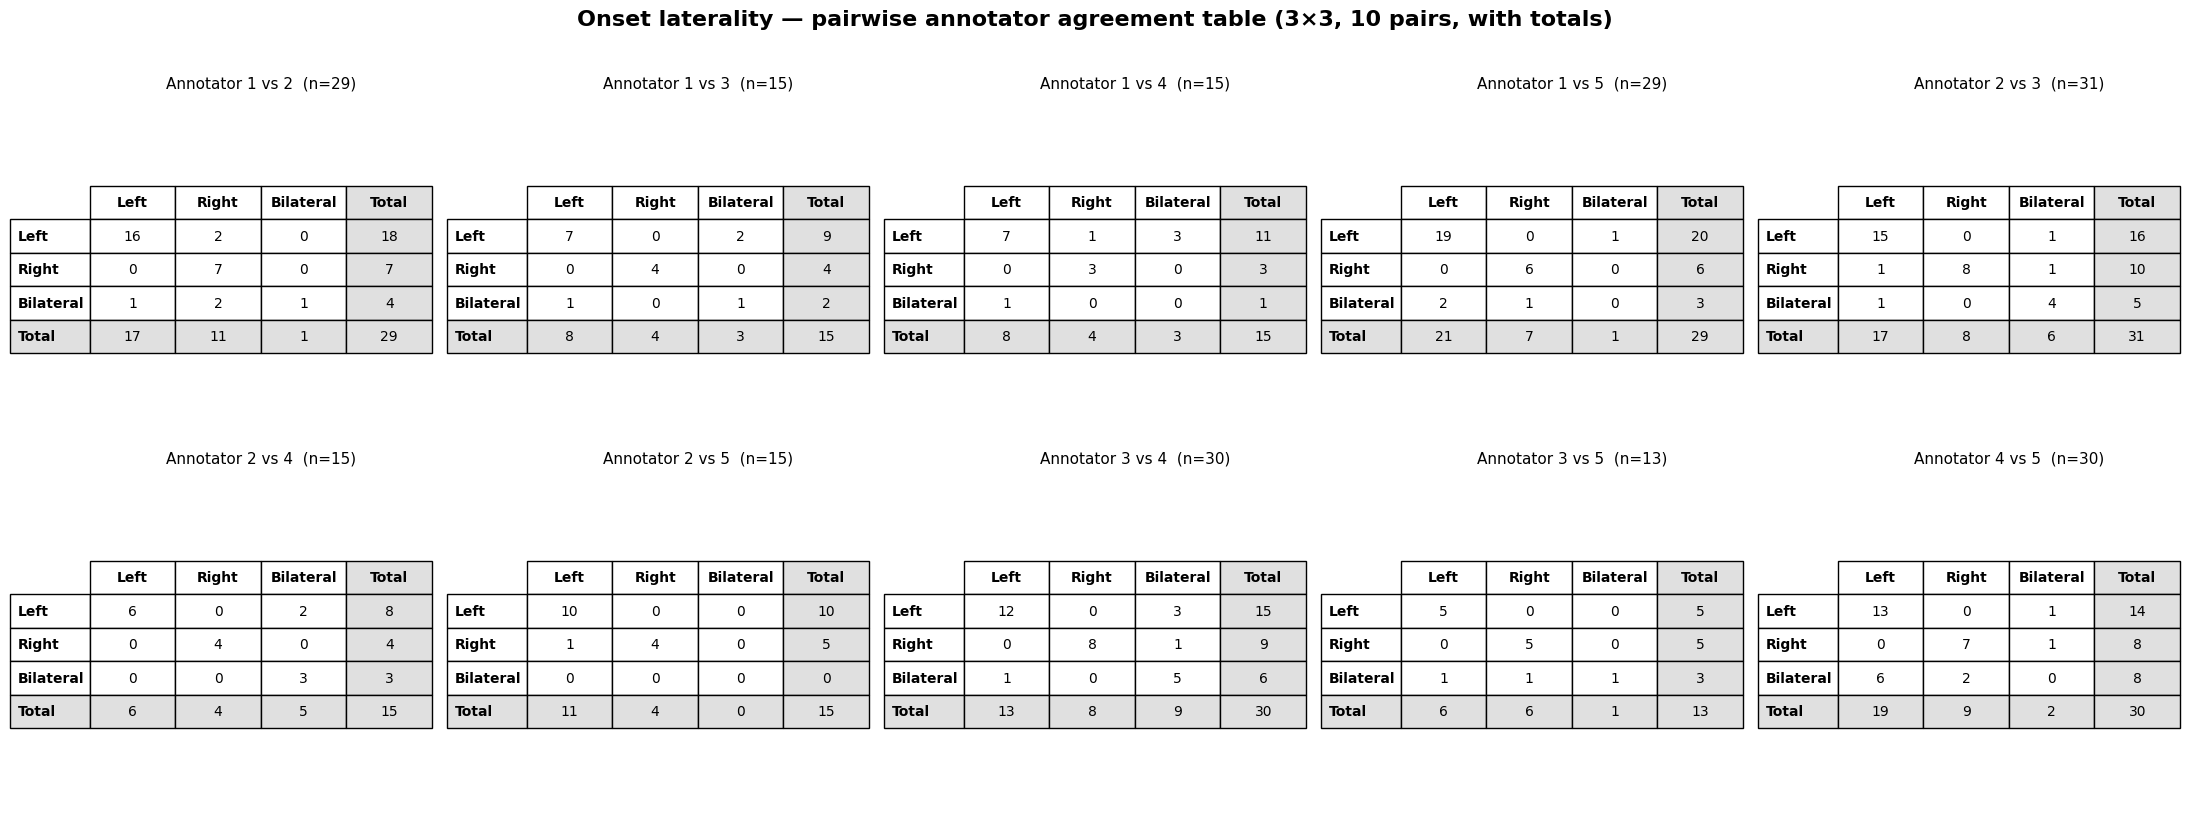

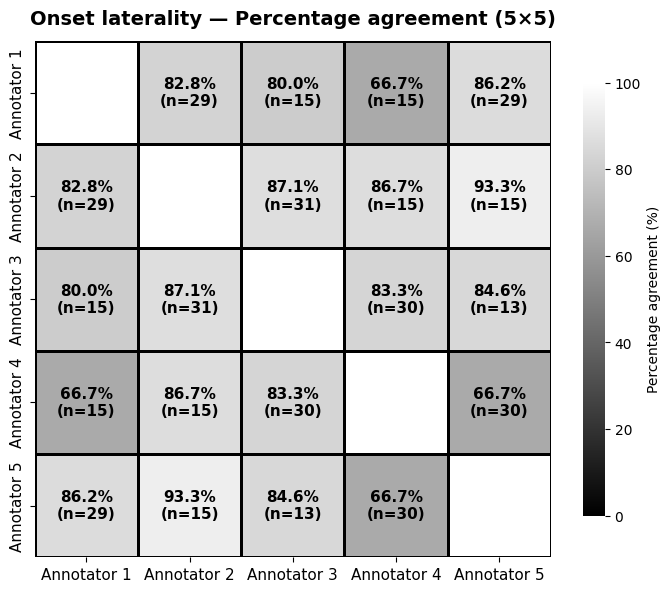

[Onset laterality — Percentage agreement (5×5)] mean pairwise percentage agreement = 81.7%


In [4]:
# ==============================================================================
#  Supplementary Figure 4A — onset laterality: pairwise tables + percentage agreement
# ==============================================================================
# ── (A) Onset laterality: 3x3 table x 10 pairs (+Total) ────────────────────
_plot_pairwise_grid_table(consensus_df, ['Left', 'Right', 'Bilateral'], _map_to_group,
                          "Onset laterality — pairwise annotator agreement table (3×3, 10 pairs, with totals)")

# ── (B) Onset laterality ────────────────────────────────────────────────────
pa_lat, n_lat = _percentage_agreement_matrix(consensus_df, _map_to_group,
                                              ['Left', 'Right', 'Bilateral'])
_plot_pa_matrix(pa_lat, n_lat, "Onset laterality — Percentage agreement (5×5)")


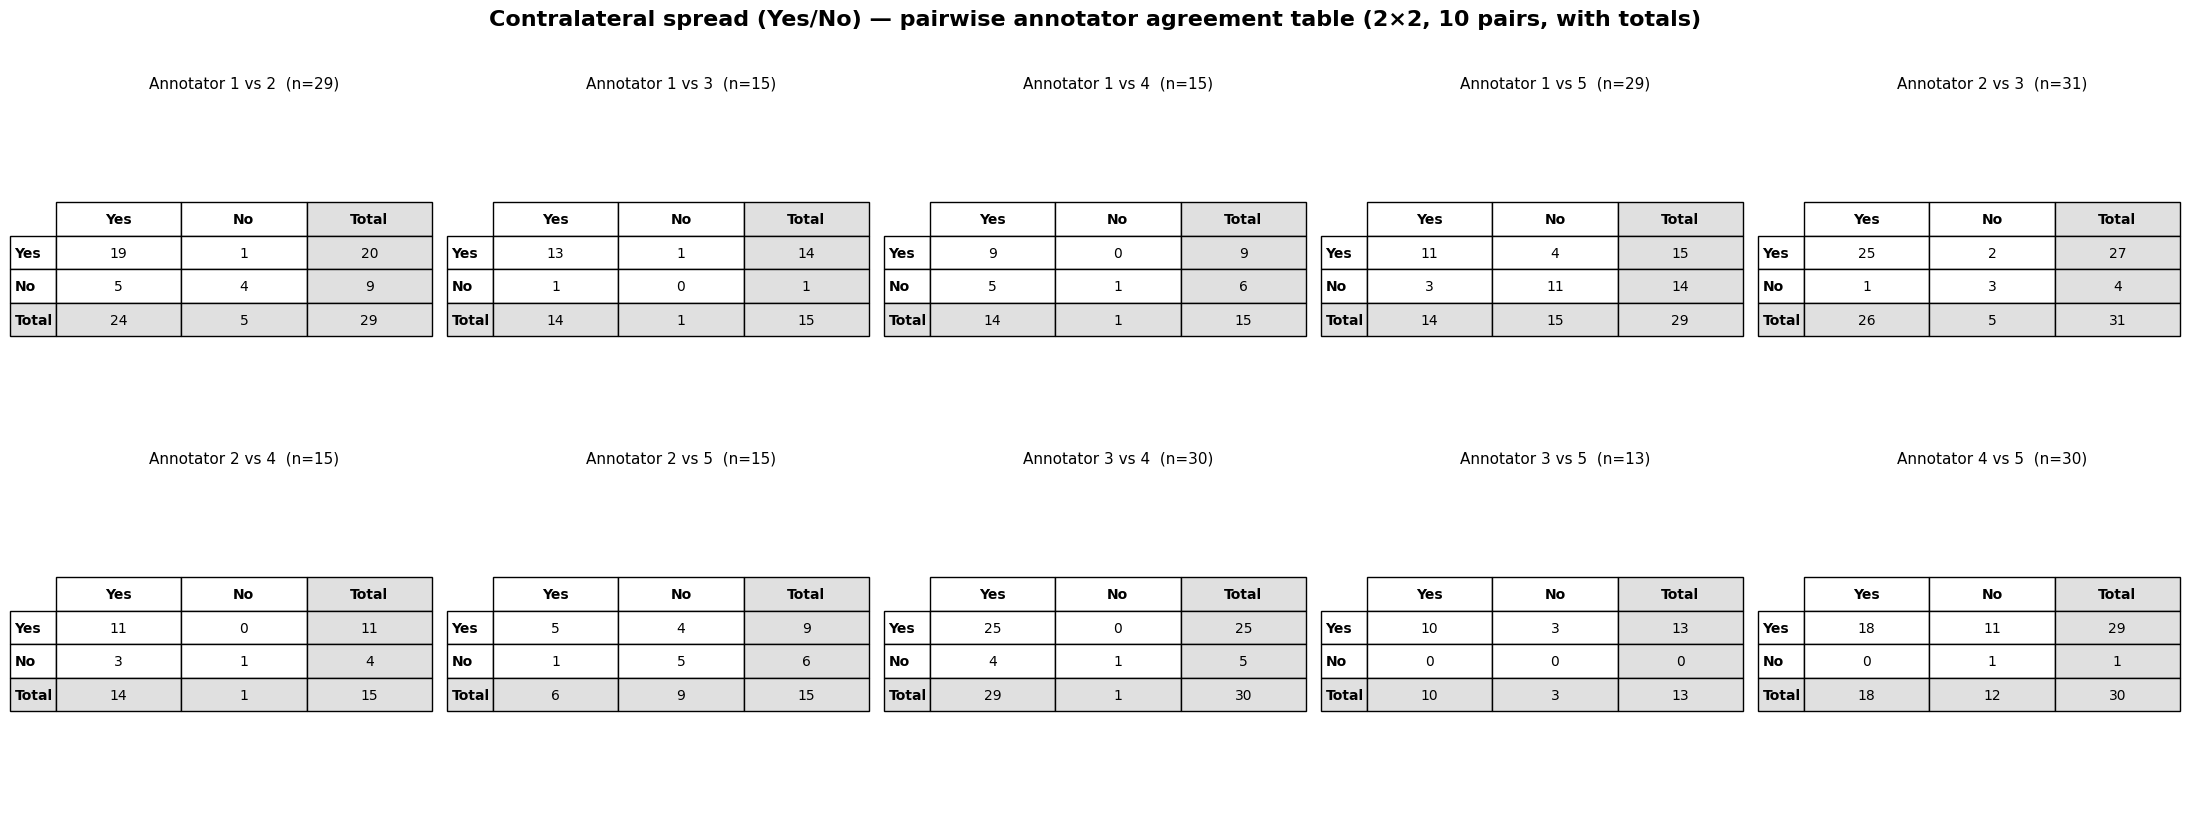

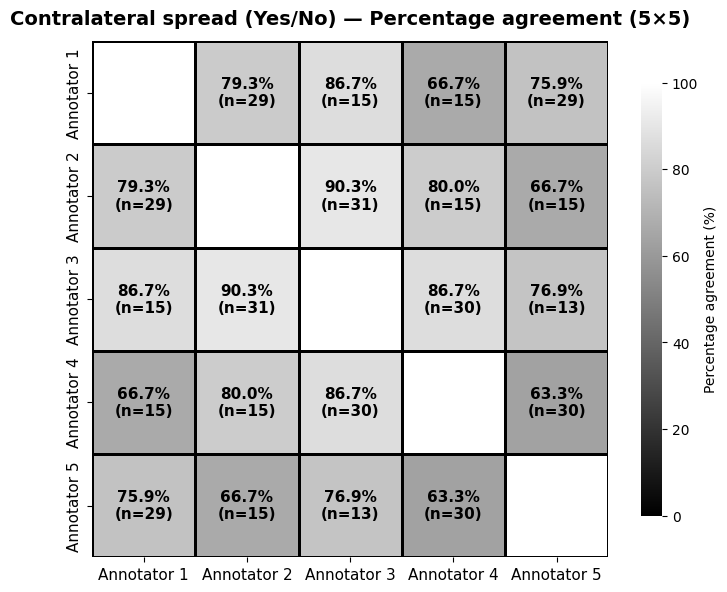

[Contralateral spread (Yes/No) — Percentage agreement (5×5)] mean pairwise percentage agreement = 77.2%


In [5]:
# ==============================================================================
#  Supplementary Figure 4B — contralateral spread: pairwise tables + percentage agreement
# ==============================================================================
# ── (B) Contralateral spread: 2x2 table x 10 pairs (+Total) ────────────────
_plot_pairwise_grid_table(consensus_df, ['Yes', 'No'], get_spread_bilateral_yes,
                          "Contralateral spread (Yes/No) — pairwise annotator agreement table (2×2, 10 pairs, with totals)")

# ── (C) Contralateral spread (Yes/No) ───────────────────────────────────────
pa_spr, n_spr = _percentage_agreement_matrix(consensus_df, get_spread_bilateral_yes,
                                              ['Yes', 'No'])
_plot_pa_matrix(pa_spr, n_spr, "Contralateral spread (Yes/No) — Percentage agreement (5×5)")


In [6]:
# ==============================================================================
#  Helpers for Supplementary Figure 5 — channel-level kappa / LMM (no figure)
# ==============================================================================
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
# from sklearn.metrics import cohen_kappa_score

ALL_CHANNELS = [
    "Fp1-F9", "F9-T9", "T9-P9", "P9-O1",
    "Fp1-F7", "F7-T7", "T7-P7", "P7-O1",
    "Fp1-F3", "F3-C3", "C3-P3", "P3-O1",
    "Fz-Cz", "Cz-Pz",
    "Fp2-F4", "F4-C4", "C4-P4", "P4-O2",
    "Fp2-F8", "F8-T8", "T8-P8", "P8-O2",
    "Fp2-F10", "F10-T10", "T10-P10", "P10-O2"
]
_CHANNEL_NORM = {ch.lower(): ch for ch in ALL_CHANNELS}

# ─────────────────────────────────────────────
# Utilities
# ─────────────────────────────────────────────
# Annotators used the old 10-20 names (T3/T5/T4/T6), while ALL_CHANNELS uses the new names (T7/P7/T8/P8).
# Convert per electrode to reconcile the two naming systems: T3->T7, T5->P7, T4->T8, T6->P8
_OLD_TO_NEW_ELECTRODE = {'T3': 'T7', 'T5': 'P7', 'T4': 'T8', 'T6': 'P8'}

def normalize_channel_name(ch_str):
    # quotes/brackets are ignored: DIFFUSE expansions are stored in the CSV as "'FP1-F9', 'F9-T9', ..."
    s = str(ch_str).replace("'", "").replace('"', "").replace("[", "").replace("]", "").strip()
    s = '-'.join(_OLD_TO_NEW_ELECTRODE.get(part.strip().upper(), part.strip())
                 for part in s.split('-'))
    return _CHANNEL_NORM.get(s.lower(), s)

def safe_isna(val):
    """NaN check that handles arrays/lists/scalars"""
    if isinstance(val, (list, np.ndarray)):
        return len(val) == 0
    try:
        return pd.isna(val)
    except ValueError:
        return False

def safe_scalar(val):
    """Return the first element of an array/list, or the scalar as is"""
    if isinstance(val, (list, np.ndarray)):
        if len(val) == 0:
            return np.nan
        return val[0]
    return val

def _list_to_channel_set(cell_val):
    """DIFFUSE arrives expanded into a list of channels by the preprocessing cell.
    safe_scalar only takes the first element (collapsing to FP1-F9), so for lists of 2+ items
    the whole list is used as the channel set."""
    if isinstance(cell_val, (list, np.ndarray)) and len(cell_val) > 1:
        chans = {normalize_channel_name(str(c)) for c in cell_val if str(c).strip()}
        return chans if chans else None
    return None

def parse_onset_channel(cell_val):
    _lst = _list_to_channel_set(cell_val)
    if _lst is not None:
        return _lst
    cell_val = safe_scalar(cell_val)
    if safe_isna(cell_val):
        return None
    s = str(cell_val).strip()
    if s == "":
        return None
    s_lower = s.lower().replace("_", " ")
    if "no seizure" in s_lower:
        return 'no_seizure'
    if s_lower == "diffuse":
        return set(ALL_CHANNELS)
    channels = [normalize_channel_name(c) for c in s.split(",") if c.strip()]
    return set(channels) if channels else None

def parse_spread_channel_cell(cell, onset_col_val=None):
    _lst = _list_to_channel_set(cell)
    if _lst is not None:
        return _lst
    cell = safe_scalar(cell)
    if safe_isna(cell):
        return None
    if str(cell).strip() == "":
        return None
    s = str(cell).strip().lower()
    if s == "diffuse":
        return set(ALL_CHANNELS)
    elif s == "same":
        if onset_col_val is not None:
            onset_ch = parse_onset_channel(onset_col_val)
            if onset_ch and onset_ch != 'no_seizure':
                return onset_ch
        return None
    elif s in ("n/a", "no seizure", "no_seizure"):
        return None
    else:
        chs = [normalize_channel_name(c) for c in str(cell).split(",") if c.strip()]
        return set(chs) if chs else None

def set_to_binary_vector(channel_set):
    """Channel set → binary vector (ALL_CHANNELS order)"""
    if channel_set is None or channel_set == 'no_seizure':
        return np.zeros(len(ALL_CHANNELS), dtype=int)
    return np.array([1 if ch in channel_set else 0 for ch in ALL_CHANNELS], dtype=int)

def cohen_kappa_from_sets(set_a, set_b):
    """
    Convert two channel sets to binary vectors, then
    compute Cohen's kappa directly from the formula (without sklearn)
    """
    vec_a = set_to_binary_vector(set_a)
    vec_b = set_to_binary_vector(set_b)

    n = len(vec_a)  # = 26 (number of ALL_CHANNELS)

    # per-channel agreement
    agree = np.sum(vec_a == vec_b)
    p_o = agree / n  # observed agreement

    # p_e: probability of chance agreement
    # P(both 1) + P(both 0)
    p1_a = np.sum(vec_a == 1) / n  # probability rater A selects 1
    p1_b = np.sum(vec_b == 1) / n  # probability rater B selects 1
    p0_a = 1 - p1_a
    p0_b = 1 - p1_b

    p_e = (p1_a * p1_b) + (p0_a * p0_b)

    # kappa
    if (1 - p_e) == 0:
        return 1.0 if p_o == 1.0 else 0.0

    return (p_o - p_e) / (1 - p_e)

def majority_channel_vote(channel_sets):
    valid = [s for s in channel_sets if s is not None and s != 'no_seizure']
    if not valid:
        return None
    n = len(valid)
    counts = {}
    for s in valid:
        for ch in s:
            counts[ch] = counts.get(ch, 0) + 1
    majority = {ch for ch, cnt in counts.items() if cnt > n / 2}
    return majority if majority else None

def channel_col(df, kind, i):
    """Channel column name for channel-level kappa. Uses the KAPPA_* column (including Z-line
    Fz-Cz, Cz-Pz) if present, otherwise the original Your_* column."""
    kappa = {'onset': f'KAPPA_onset_channel_{i}', 'spread': f'KAPPA_spread_channel_{i}'}[kind]
    if kappa in df.columns:
        return kappa
    return {'onset': f'Your_onset_channel_{i}', 'spread': f'Your_contralateral_spread_channel_{i}'}[kind]

def get_valid_ids(row, df):
    """Annotators who actually rated this seizure. Uses Annotator_i if present; the github-spread
    CSV has no Annotator_i columns, so a filled Group_i is used instead (NaN = not assigned)."""
    valid_ids = []
    for i in range(1, 6):
        ann_col = f'Annotator_{i}'
        if ann_col not in df.columns:
            g = safe_scalar(row.get(f'Group_{i}', np.nan))
            if not safe_isna(g) and str(g).strip() != "":
                valid_ids.append(i)
            continue
        ann_val = safe_scalar(row.get(ann_col, np.nan))
        if not safe_isna(ann_val) and str(ann_val).strip() != "":
            valid_ids.append(i)
    return valid_ids


# ─────────────────────────────────────────────
# 1) Onset Channel Agreement (Cohen's Kappa)
# ─────────────────────────────────────────────
def calculate_onset_channel_kappa(df):
    df = ensure_onset_inclusion_cols(df)   # onset common inclusion set
    records = []
    included_rows = 0   # Inter-rater N
    n_lt2_raters  = 0   # channel sets < 2 even with valid_ids (rare)
    n_no_majority = 0   # no majority channel -> Consensus = NaN

    for idx, row in df.iterrows():
        if not row['onset_included']:
            continue
        patient_id = row.get('Patient_id', idx)

        use_ids = row['onset_valid_ids']   # has channel pairs + not no-seizure
        parsed = {}
        for num in use_ids:
            result = parse_onset_channel(row.get(channel_col(df, 'onset', num), np.nan))
            if result is None or result == 'no_seizure':
                continue
            parsed[num] = result

        valid_sets = list(parsed.values())
        if len(valid_sets) < 2:
            n_lt2_raters += 1
            continue

        included_rows += 1
        maj = majority_channel_vote(valid_sets)
        if maj is None:
            n_no_majority += 1

        # ① Inter-rater: mean of pairwise kappas
        pair_kappas = []
        for set_a, set_b in combinations(valid_sets, 2):
            k = cohen_kappa_from_sets(set_a, set_b)
            pair_kappas.append(k)
        interrater = np.mean(pair_kappas)

        # ② Consensus: mean of each rater vs majority
        if maj is not None:
            consensus_kappas = [cohen_kappa_from_sets(s, maj) for s in valid_sets]
            consensus = np.mean(consensus_kappas)
        else:
            consensus = np.nan

        records.append({
            'Patient_id':  patient_id,
            'Seizure_idx': idx,
            'Metric_Type': 'Onset_Channel',
            'Inter_rater': interrater,
            'Consensus':   consensus
        })

    consensus_n = included_rows - n_no_majority
    print(f"[Onset Channel] using common inclusion set | excluded channel set<2: {n_lt2_raters} | "
          f"Inter-rater N: {included_rows}")
    print(f"[Onset Channel] of these, no majority channel -> Consensus=NaN: {n_no_majority} | "
          f"Consensus N: {consensus_n}")
    return pd.DataFrame(records)



def calculate_spread_channel_kappa(df):
    """Spread-channel agreement per seizure (same criteria as the per-annotator spread cell).
    Seizures: common onset inclusion set (onset_included); Majority_Group is NOT required.
    Annotators: onset_valid_ids who reported a spread (finite spread_time; bilateral onset = 0 s ->
    all channels). Annotators with no spread (inf) are left out instead of dropping the seizure.
    Needs >=2 annotators with a spread channel set; no majority channel -> Consensus = NaN."""
    df = ensure_onset_inclusion_cols(df)
    records = []
    included_rows = 0   # Inter-rater N
    n_lt2_sets    = 0   # fewer than 2 annotators with a spread channel set
    n_no_majority = 0   # no majority channel -> Consensus = NaN

    for idx, row in df.iterrows():
        if not row['onset_included']:
            continue
        patient_id = row.get('Patient_id', idx)

        spread_sets = []
        for i in row['onset_valid_ids']:
            v = safe_scalar(row.get(f'spread_time_{i}', np.nan))
            if safe_isna(v) or np.isinf(float(v)):
                continue
            if float(v) == 0.0:
                spread_sets.append(set(ALL_CHANNELS))
                continue
            spread_col = channel_col(df, 'spread', i)
            onset_col  = channel_col(df, 'onset', i)
            if spread_col not in df.columns:
                continue
            result = parse_spread_channel_cell(row.get(spread_col, np.nan),
                                               onset_col_val=row.get(onset_col, np.nan))
            if result is not None:
                spread_sets.append(result)

        if len(spread_sets) < 2:
            n_lt2_sets += 1
            continue

        included_rows += 1
        maj = majority_channel_vote(spread_sets)
        if maj is None:
            n_no_majority += 1

        pair_kappas = [cohen_kappa_from_sets(a, b) for a, b in combinations(spread_sets, 2)]
        interrater = np.mean(pair_kappas)
        consensus = (np.mean([cohen_kappa_from_sets(s, maj) for s in spread_sets])
                     if maj is not None else np.nan)

        records.append({
            'Patient_id':  patient_id,
            'Seizure_idx': idx,
            'Metric_Type': 'Spread_Channel',
            'Inter_rater': interrater,
            'Consensus':   consensus
        })

    consensus_n = included_rows - n_no_majority
    print(f"[Spread Channel] using common inclusion set | excluded <2 annotators with spread: {n_lt2_sets} | "
          f"Inter-rater N: {included_rows}")
    print(f"[Spread Channel] of these, no majority channel -> Consensus=NaN: {n_no_majority} | "
          f"Consensus N: {consensus_n}")
    return pd.DataFrame(records)
# ─────────────────────────────────────────────
# 3) LME model
# ─────────────────────────────────────────────
def run_lme(df_records, metric_type_label, agreement_col='Inter_rater'):
    data = df_records[['Patient_id', agreement_col]].dropna().copy()
    data.columns = ['Patient_id', 'Agreement']

    if data.shape[0] < 5:
        print(f"[{metric_type_label} - {agreement_col}] insufficient data")
        return None

    n_per_patient = data.groupby('Patient_id').size()
    single = (n_per_patient == 1).sum()
    if single > 0:
        print(f"  ※ {single} patients have only 1 seizure")

    # --- Seizure level (LME) ---
    model  = smf.mixedlm("Agreement ~ 1", data=data, groups=data['Patient_id'])
    result = model.fit(reml=True)

    var_patient  = float(result.cov_re.iloc[0, 0])
    var_residual = float(result.scale)
    icc          = var_patient / (var_patient + var_residual)
    sz_mean      = result.fe_params['Intercept']
    sz_ci_low    = result.conf_int().loc['Intercept', 0]
    sz_ci_high   = result.conf_int().loc['Intercept', 1]

    # --- Patient level (per-patient mean, then simple mean ± 95% CI) ---
    patient_means = data.groupby('Patient_id')['Agreement'].mean()
    arr           = patient_means.values
    pt_mean       = np.mean(arr)
    pt_ci         = 1.96 * np.std(arr, ddof=1) / np.sqrt(len(arr))
    pt_ci_low     = pt_mean - pt_ci
    pt_ci_high    = pt_mean + pt_ci

    print(f"\n{'='*55}")
    print(f"[{metric_type_label} | {agreement_col}]")
    print(f"  --- Seizure Level (LME) ---")
    print(f"  N seizures : {data.shape[0]}")
    print(f"  N patients : {data['Patient_id'].nunique()}")
    print(f"  Mean κ     : {sz_mean:.4f} (95% CI: {sz_ci_low:.4f}–{sz_ci_high:.4f})")
    print(f"  ICC        : {icc:.4f}")
    print(f"  --- Patient Level (simple mean ± 95% CI) ---")
    print(f"  N patients : {len(arr)}")
    print(f"  Mean κ     : {pt_mean:.4f} (95% CI: {pt_ci_low:.4f}–{pt_ci_high:.4f})")
    print(f"{'='*55}\n")

    return {
        'seizure': {'mean': sz_mean, 'ci_low': sz_ci_low,  'ci_high': sz_ci_high, 'icc': icc},
        'patient': {'mean': pt_mean, 'ci_low': pt_ci_low,  'ci_high': pt_ci_high}
    }
# ─────────────────────────────────────────────
# 4) Visualization (Seizure level + Patient level)
# ─────────────────────────────────────────────
def plot_kappa_two_levels(onset_df, spread_df, lme_stats):
    unified_grey = "#A9A9A9"

    onset_patient  = onset_df.groupby('Patient_id')[['Inter_rater','Consensus']].mean().reset_index()
    spread_patient = spread_df.groupby('Patient_id')[['Inter_rater','Consensus']].mean().reset_index()

    fig, axes = plt.subplots(2, 2, figsize=(12, 12), sharey=True)
    sns.set_style("white")

    configs = [
        (axes[0, 0], onset_df,       'Onset Channel – Seizure Level',  'Onset_Channel',  'seizure'),
        (axes[0, 1], onset_patient,  'Onset Channel – Patient Level',   'Onset_Channel',  'patient'),
        (axes[1, 0], spread_df,      'Spread Channel – Seizure Level',  'Spread_Channel', 'seizure'),
        (axes[1, 1], spread_patient, 'Spread Channel – Patient Level',  'Spread_Channel', 'patient'),
    ]

    for ax, data, title, metric_key, level in configs:
        plot_df = data.melt(
            id_vars='Patient_id',
            value_vars=['Inter_rater', 'Consensus'],
            var_name='Metric', value_name='Kappa'
        )
        plot_df['Metric'] = plot_df['Metric'].map({
            'Inter_rater': 'Inter-rater',
            'Consensus':   'Consensus'
        })

        sns.boxplot(
            x='Metric', y='Kappa', data=plot_df,
            order=['Inter-rater', 'Consensus'],
            ax=ax, width=0.4, showfliers=False, linewidth=2,
            medianprops={'color': '#333333', 'linewidth': 3},
            boxprops={'facecolor': 'none', 'edgecolor': unified_grey},
            whiskerprops={'color': unified_grey},
            capprops={'color': unified_grey}
        )

        sns.stripplot(
            x='Metric', y='Kappa', data=plot_df,
            order=['Inter-rater', 'Consensus'],
            ax=ax, color=unified_grey, jitter=0.2, size=7, alpha=0.5
        )

        # Mean ± 95% CI
        for i, metric_col in enumerate(['Inter_rater', 'Consensus']):
            if (lme_stats
                    and metric_key in lme_stats
                    and metric_col in lme_stats[metric_key]
                    and level in lme_stats[metric_key][metric_col]):
                s = lme_stats[metric_key][metric_col][level]
                ax.errorbar(
                    i, s['mean'],
                    yerr=[[s['mean'] - s['ci_low']], [s['ci_high'] - s['mean']]],
                    fmt='D', color='black', markersize=8,
                    capsize=6, linewidth=2,
                    label='Mean ± 95% CI' if i == 0 else ''
                )

        n = len(data)
        ax.set_title(f"{title}\n(N={n})", fontsize=11, pad=10)
        ax.set_xlabel("")
        ax.set_ylabel("Cohen's Kappa" if ax in [axes[0, 0], axes[1, 0]] else "",
                      fontsize=11)
        ax.set_ylim(-0.5, 1.05)
        ax.legend(fontsize=8, loc='lower right')
        sns.despine(ax=ax)

    plt.suptitle("Channel Agreement (Cohen's Kappa)",
                 fontsize=14, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.show()


In [7]:
# ==============================================================================
#  Helper — spread_time_i per annotator (calculate_detailed_metrics; no figure)
# ==============================================================================
#Fig3B
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from itertools import combinations

def calculate_detailed_metrics(df):
    # --- [Step 1] compute actual spread time ---
    for i in range(1, 6):
        group_col = f'Group_{i}'
        onset_col = f'Your_onset_time (s)_{i}'
        spread_raw_col = f'Your_contralateral_spread_time (s)_{i}'
        
        # new column
        time_out_col = f'spread_time_{i}'
        
        def get_actual_time(row):
            group_val = str(row[group_col]).lower() if pd.notna(row[group_col]) else ""
            
            # 1. no data or No seizure -> excluded
            if group_val == "" or "no seizure" in group_val:
                return np.nan
            
            # 2. Generalized / Bilateral -> 0.0 (immediate spread)
            if 'generalized' in group_val or 'bilateral' in group_val:
                return 0.0
            
            # 3. Only Left / Only Right -> np.inf (no spread)
            if 'only left' in group_val or 'only right' in group_val:
                return np.inf
            
            # 4. otherwise: try numeric computation (including Diffuse)
            spread_raw = str(row[spread_raw_col]).strip().lower() if pd.notna(row[spread_raw_col]) else ""
            
            if 'diffuse' in spread_raw:
                return 0.0
            
            onset = pd.to_numeric(row[onset_col], errors='coerce')
            spread_num = pd.to_numeric(spread_raw, errors='coerce')
            
            if pd.notna(spread_num) and pd.notna(onset):
                return abs(spread_num - onset)
            
            # none of the above (e.g., spread time is empty)
            return np.inf

        df[time_out_col] = df.apply(get_actual_time, axis=1)

    # --- [Step 2] agreement score ---
    interrater_results = []
    consensus_results = []

    for index, row in df.iterrows():
        time_cols = [f'spread_time_{i}' for i in range(1, 5)]
        active_times = [row[c] for c in time_cols if pd.notna(row[c])]

        if len(active_times) < 2:
            interrater_results.append(np.nan)
            consensus_results.append(np.nan)
            continue

        # score transform: 1 / (time + 1)
        # 0.0 (Bilateral) -> score 1.0
        # np.inf (Only side) -> score 0.0
        scores = []
        for t in active_times:
            if t == np.inf:
                scores.append(0.0)
            else:
                scores.append(1 / (t + 1))
        
        # Consensus: similarity to the median (1 - distance)
        med_score = np.median(scores)
        consensus_results.append(np.mean([1 - abs(s - med_score) for s in scores]))

        # Inter-rater: mean pairwise similarity
        i_scores = []
        for s1, s2 in combinations(scores, 2):
            i_scores.append(1 - abs(s1 - s2))
        interrater_results.append(np.mean(i_scores))

    plot_df = pd.DataFrame({
        'Metric': ['Inter-rater'] * len(interrater_results) + ['Consensus'] * len(consensus_results),
        'Agreement (0-1)': interrater_results + consensus_results
    }).dropna()
    
    return plot_df, df

# --- run and check results ---
final_plot_df, updated_df = calculate_detailed_metrics(consensus_df)

[Onset Channel] using common inclusion set | excluded channel set<2: 0 | Inter-rater N: 78
[Onset Channel] of these, no majority channel -> Consensus=NaN: 2 | Consensus N: 76
[Spread Channel] using common inclusion set | excluded <2 annotators with spread: 20 | Inter-rater N: 58
[Spread Channel] of these, no majority channel -> Consensus=NaN: 2 | Consensus N: 56
  ※ 18 patients have only 1 seizure

[Onset_Channel | Inter_rater]
  --- Seizure Level (LME) ---
  N seizures : 78
  N patients : 48
  Mean κ     : 0.5688 (95% CI: 0.5028–0.6348)
  ICC        : 0.0741
  --- Patient Level (simple mean ± 95% CI) ---
  N patients : 48
  Mean κ     : 0.5635 (95% CI: 0.4994–0.6276)

  ※ 18 patients have only 1 seizure



[Onset_Channel | Consensus]
  --- Seizure Level (LME) ---
  N seizures : 76
  N patients : 47
  Mean κ     : 0.7802 (95% CI: 0.7451–0.8153)
  ICC        : 0.0000
  --- Patient Level (simple mean ± 95% CI) ---
  N patients : 47
  Mean κ     : 0.7757 (95% CI: 0.7422–0.8092)

  ※ 16 patients have only 1 seizure

[Spread_Channel | Inter_rater]
  --- Seizure Level (LME) ---
  N seizures : 58
  N patients : 37
  Mean κ     : 0.3803 (95% CI: 0.2891–0.4715)
  ICC        : 0.0000
  --- Patient Level (simple mean ± 95% CI) ---
  N patients : 37
  Mean κ     : 0.3803 (95% CI: 0.2897–0.4708)

  ※ 18 patients have only 1 seizure

[Spread_Channel | Consensus]
  --- Seizure Level (LME) ---
  N seizures : 56
  N patients : 37
  Mean κ     : 0.6659 (95% CI: 0.6097–0.7220)
  ICC        : 0.0962
  --- Patient Level (simple mean ± 95% CI) ---
  N patients : 37
  Mean κ     : 0.6647 (95% CI: 0.6039–0.7254)


=== Seizure level (LMM, patient random intercept; 95% CI) ===
onset inter-rater κ = 0.57 [0.50–0.6

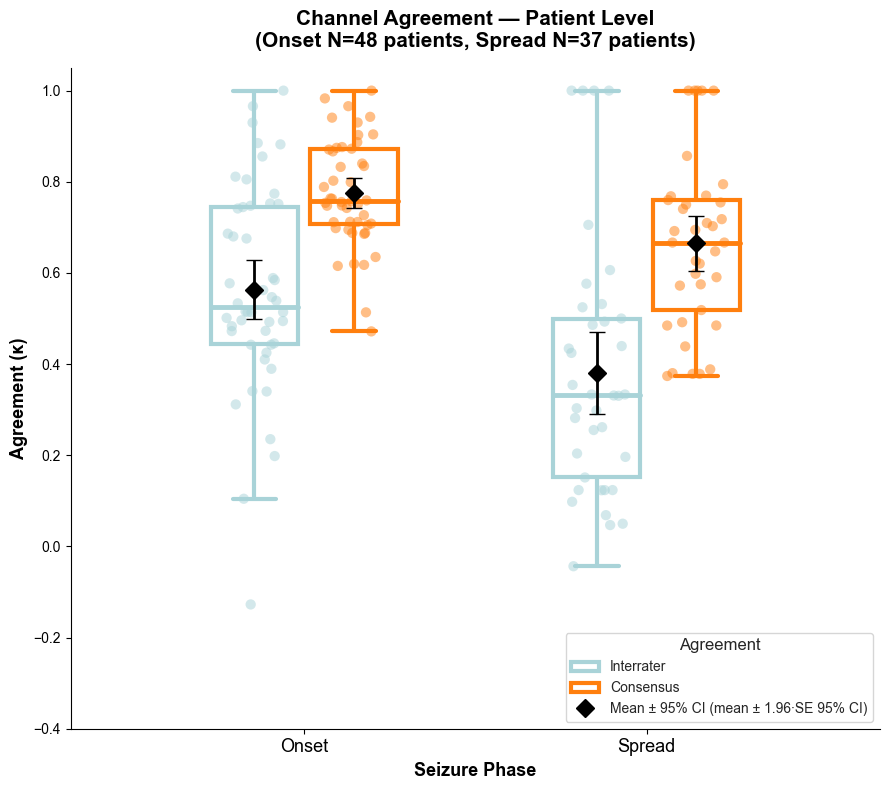

In [8]:
# ==============================================================================
#  Supplementary Figure 5 — channel agreement (Cohen's κ), patient level
# ==============================================================================
#updates July 25, 2026
# ─────────────────────────────────────────────
# 4) Visualization (single panel: Onset vs Spread, narrow spacing + thick boxes + fixed colors)
# ─────────────────────────────────────────────
def plot_kappa_single_panel(onset_df, spread_df, lme_stats, level='seizure'):
    """
    level='seizure' : 1 seizure = 1 point, Mean ± 95% CI = LMM (patient random intercept)
    level='patient' : 1 patient = 1 point (per-patient mean), Mean ± 95% CI = mean ± 1.96·SE
    (CI uses lme_stats from run_lme as is -> always matches the print below)
    """
    dark_gray = "#A9D3D8"   # light blue (Inter-rater)
    grey      = "#ff7f0e"   # orange     (Consensus)

    def _vals(df, col):
        if level == 'seizure':
            return df[col].dropna().values
        return df.groupby('Patient_id')[col].mean().dropna().values

    onset_inter,  onset_consens  = _vals(onset_df,  'Inter_rater'), _vals(onset_df,  'Consensus')
    spread_inter, spread_consens = _vals(spread_df, 'Inter_rater'), _vals(spread_df, 'Consensus')

    if level == 'seizure':
        n_onset, n_spread = len(onset_df), len(spread_df)
        unit = 'seizures'
    else:
        n_onset, n_spread = onset_df['Patient_id'].nunique(), spread_df['Patient_id'].nunique()
        unit = 'patients'

    # ── positions (narrow spacing) ──
    box_width   = 0.28
    pair_gap    = 0.32
    group_gap   = 1.1
    onset_center  = 0
    spread_center = onset_center + group_gap

    pos_onset_inter    = onset_center  - pair_gap / 2
    pos_onset_consens  = onset_center  + pair_gap / 2
    pos_spread_inter   = spread_center - pair_gap / 2
    pos_spread_consens = spread_center + pair_gap / 2

    fig, ax = plt.subplots(figsize=(9, 8))
    sns.set_style("white")

    box_data = [
        ('Onset_Channel',  'Inter_rater', onset_inter,    pos_onset_inter,    dark_gray),
        ('Onset_Channel',  'Consensus',   onset_consens,  pos_onset_consens,  grey),
        ('Spread_Channel', 'Inter_rater', spread_inter,   pos_spread_inter,   dark_gray),
        ('Spread_Channel', 'Consensus',   spread_consens, pos_spread_consens, grey),
    ]

    # ── Boxplot ──
    for _k, _c, data, pos, color in box_data:
        if len(data) == 0:
            continue
        ax.boxplot(
            data, positions=[pos], widths=box_width,
            patch_artist=True, showfliers=False,
            medianprops={'color': color, 'linewidth': 3.5},
            boxprops={'facecolor': 'none', 'edgecolor': color, 'linewidth': 3},
            whiskerprops={'color': color, 'linewidth': 3},
            capprops={'color': color, 'linewidth': 3}
        )

    # ── Strip points (jitter) ──
    rng = np.random.default_rng(42)
    for _k, _c, data, pos, color in box_data:
        if len(data) == 0:
            continue
        jitter = rng.uniform(-box_width * 0.35, box_width * 0.35, size=len(data))
        ax.scatter(pos + jitter, data, color=color, alpha=0.5, s=55,
                   edgecolors='none', zorder=3)

    # ── Mean ± 95% CI (black diamond) ──
    for metric_key, col, _data, pos, _color in box_data:
        if lme_stats and metric_key in lme_stats and col in lme_stats[metric_key]:
            st = lme_stats[metric_key][col][level]
            ax.errorbar(
                pos, st['mean'],
                yerr=[[st['mean'] - st['ci_low']], [st['ci_high'] - st['mean']]],
                fmt='D', color='black', markersize=9, capsize=6, linewidth=2, zorder=4
            )

    # ── axes ──
    ax.set_xticks([onset_center, spread_center])
    ax.set_xticklabels(['Onset', 'Spread'], fontsize=13)
    ax.set_xlim(onset_center - 0.75, spread_center + 0.75)

    ci_name = 'LMM 95% CI' if level == 'seizure' else 'mean ± 1.96·SE 95% CI'
    ax.set_title(
        f"Channel Agreement — {level.capitalize()} Level\n"
        f"(Onset N={n_onset} {unit}, Spread N={n_spread} {unit})",
        fontsize=15, fontweight='bold', pad=15
    )
    ax.set_xlabel("Seizure Phase", fontsize=13, fontweight='bold')
    ax.set_ylabel("Agreement (κ)", fontsize=13, fontweight='bold')
    ax.set_ylim(-0.4, 1.05)

    # ── legend ──
    from matplotlib.patches import Patch
    from matplotlib.lines import Line2D
    legend_elems = [
        Patch(facecolor='white', edgecolor=dark_gray, linewidth=3, label='Interrater'),
        Patch(facecolor='white', edgecolor=grey, linewidth=3, label='Consensus'),
        Line2D([0], [0], marker='D', color='black', linestyle='', markersize=9,
               label=f'Mean ± 95% CI ({ci_name})'),
    ]
    ax.legend(handles=legend_elems, title='Agreement', fontsize=10,
              title_fontsize=12, loc='lower right', frameon=True)

    sns.despine(ax=ax)
    plt.tight_layout()
    plt.show()


def print_kappa_summary(onset_df, spread_df, lme_stats):
    """Print seizure level / patient level separately in a manuscript-ready format."""
    def _n(df, col):
        d = df[df[col].notna()]
        return len(d), d['Patient_id'].nunique()

    def _fmt(st):
        return f"{st['mean']:.2f} [{st['ci_low']:.2f}–{st['ci_high']:.2f}]"

    items = [('onset',  'inter-rater', onset_df,  'Onset_Channel',  'Inter_rater'),
             ('onset',  'consensus',   onset_df,  'Onset_Channel',  'Consensus'),
             ('spread', 'inter-rater', spread_df, 'Spread_Channel', 'Inter_rater'),
             ('spread', 'consensus',   spread_df, 'Spread_Channel', 'Consensus')]

    for level in ('seizure', 'patient'):
        head = ('Seizure level (LMM, patient random intercept; 95% CI)' if level == 'seizure'
                else 'Patient level (per-patient mean; mean ± 1.96·SE 95% CI)')
        print(f"\n=== {head} ===")
        parts = []
        for phase, metric, df_k, label, col in items:
            st = lme_stats[label][col][level]
            n_sz, n_pt = _n(df_k, col)
            n_txt = f"N = {n_sz} seizures / {n_pt} patients" if level == 'seizure' else f"N = {n_pt} patients"
            parts.append(f"{phase} {metric} κ = {_fmt(st)}, {n_txt}")
        print(";\n".join(parts) + ".")


# ─────────────────────────────────────────────
# Run
# ─────────────────────────────────────────────
consensus_df = consensus_df.reset_index(drop=True)

# spread_time_1..5 columns are created by cell 13 (calculate_detailed_metrics).
# Without them calculate_spread_channel_kappa skips every row and returns nothing → create them first.
if not all(f'spread_time_{_i}' in consensus_df.columns for _i in range(1, 6)):
    if 'calculate_detailed_metrics' not in globals():
        raise RuntimeError(
            'spread_time_* columns are missing and calculate_detailed_metrics is not defined. '
            'Run cell 13 (Fig3B) first.')
    print('[guard] spread_time_* columns missing → creating them with calculate_detailed_metrics')
    _, consensus_df = calculate_detailed_metrics(consensus_df)

onset_kappa_df  = calculate_onset_channel_kappa(consensus_df)
spread_kappa_df = calculate_spread_channel_kappa(consensus_df)

lme_stats = {}
for df_k, label in [(onset_kappa_df,  'Onset_Channel'),
                    (spread_kappa_df, 'Spread_Channel')]:
    lme_stats[label] = {}
    for col in ['Inter_rater', 'Consensus']:
        res = run_lme(df_k, label, agreement_col=col)
        if res:
            lme_stats[label][col] = res

print_kappa_summary(onset_kappa_df, spread_kappa_df, lme_stats)
plot_kappa_single_panel(onset_kappa_df, spread_kappa_df, lme_stats, level='patient')


In [9]:
# ==============================================================================
#  Helper — channel agreement / spread MAD (calculate_channel_agreement; no figure)
# ==============================================================================
import pandas as pd
import numpy as np
from itertools import combinations
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from collections import Counter


# ── Common helpers ─────────────────────────────────────────────────────────────────
# NOTE: the kappa cell (calculate_onset_channel_kappa etc.) also defines normalize_channel_name / majority_channel_vote.
#       Redefining them under the same names would make later kappa recomputations use this (different)
#       version and change the values, so the ones in this cell use a separate _ca_ prefix.

def _ca_normalize_channel_name(ch_str):
    # quotes/brackets are ignored (DIFFUSE expansions are stored as "'FP1-F9', 'F9-T9', ...")
    return str(ch_str).replace("'", "").replace('"', "").replace("[", "").replace("]", "").strip()


def parse_channel_string(cell_val, onset_channels=None):
    if isinstance(cell_val, (pd.Series, np.ndarray, list)):
        cell_val = cell_val.iloc[0] if isinstance(cell_val, pd.Series) else cell_val[0]
    if pd.isna(cell_val):
        return None
    s = str(cell_val).strip()
    if s == "" or s.lower() == "n/a":
        return None
    if s.lower() == "same":
        return set(onset_channels) if onset_channels else None
    channels = [_ca_normalize_channel_name(c) for c in s.split(",") if c.strip()]
    return set(channels) if channels else None


def jaccard(set_a, set_b):
    if not set_a and not set_b:
        return 1.0
    if not set_a or not set_b:
        return 0.0
    intersection = len(set_a & set_b)
    union = len(set_a | set_b)
    return intersection / union if union > 0 else 0.0


def _ca_majority_channel_vote(channel_sets):
    valid = [s for s in channel_sets if s is not None]
    if not valid:
        return None
    n = len(valid)
    channel_counts = {}
    for s in valid:
        for ch in s:
            channel_counts[ch] = channel_counts.get(ch, 0) + 1
    majority = {ch for ch, cnt in channel_counts.items() if cnt > n / 2}
    return majority if majority else None


def resolve_same_channels(df):
    df = df.copy()
    for i in range(1, 6):
        onset_col  = f'Your_onset_channel_{i}'
        spread_col = f'Your_contralateral_spread_channel_{i}'
        if onset_col not in df.columns or spread_col not in df.columns:
            continue
        mask = df[spread_col].astype(str).str.strip().str.lower() == 'same'
        df.loc[mask, spread_col] = df.loc[mask, onset_col]
    return df


def _spread_category(label):
    """
    Ignores onset side (left/right) entirely; only checks whether spread_time is inf (= no spread)
    or numeric (= spread_time computable). spread_time=0 for generalized/bilateral
    is "immediate by definition" but still numeric, so it is grouped with measured 'X to spread' values
    and used together in the MAD (a large gap between 0 and a measured value shows up as a large MAD,
    so it does not need to be split out as Disagreement).
    """
    if label in ('only left', 'only right'):
        return 'no_spread'      # spread_time = inf (no spread)
    if label in ('generalized/bilateral', 'left to spread', 'right to spread'):
        return 'spread_time'    # spread_time = number (0 or measured value)
    return None                 # no seizure / other


def classify_spread_times(row):
    """
    Ignores onset laterality (which side) entirely and decides only by whether spread_time is inf or numeric
    (no_spread vs spread_time). Responding annotators are split into the two categories and
    the category with more raters (>=2) wins by majority (tie -> disagreement):

      no_spread   majority -> 'all_inf'  (green "no spread" consensus. spread_time=inf so MAD
                           cannot be computed, but raters agreed on 'no spread', so not disagreement)
      spread_time majority -> MAD from that group's spread_time values (0 or measured) ('normal')
      no majority (fewer than 2 responses, or a tie between categories) -> 'disagreement'

    e.g.) bilateral(0) + right-to-spread(6.2) + only-right(inf)
        -> 2 raters in spread_time category (0, 6.2) -> MAD = |6.2-0|/2 = 3.1 (disagreement expressed numerically)
        only-left + only-right + bilateral
        -> 2 raters no_spread (only-left, only-right) -> 'all_inf' (green)
    """
    members = {}   # category -> {annotator_id: spread_time}
    for i in range(1, 6):
        g = row.get(f'Group_{i}')
        if not isinstance(g, str):
            continue
        cat = _spread_category(g)
        if cat is None:
            continue
        st = row.get(f'spread_time_{i}', np.nan)
        if pd.isna(st):
            continue
        members.setdefault(cat, {})[i] = float(st)

    if not members:
        return [], 'disagreement', np.nan, 'disagreement'

    counts = {c: len(v) for c, v in members.items()}
    max_n = max(counts.values())
    top_cats = [c for c, n in counts.items() if n == max_n]

    if max_n < 2 or len(top_cats) > 1:
        return [], 'disagreement', np.nan, 'disagreement'

    cat = top_cats[0]
    grp = members[cat]
    ids = list(grp.keys())

    if cat == 'no_spread':
        return ids, 'all_inf', np.nan, np.nan

    arr = np.array(list(grp.values()))
    mad = float(np.median(np.abs(arr - np.median(arr))))
    return ids, 'normal', mad, mad


def get_laterality(row):
    mg = str(row.get('Majority_Group', '')).strip().lower()
    if 'no seizure' in mg or 'no_seizure' in mg:
        return 'no_seizure'
    if 'left' in mg:
        return 'left'
    if 'right' in mg:
        return 'right'
    if 'bilateral' in mg or 'generalized' in mg or 'general' in mg:
        return 'bilateral'
    return 'high_disagreement'


# ── Disagreement subgroup classification helpers ──────────────────────────────────────────

# (old) category()/is_spread() split disagreement into 4 subtypes by onset laterality
# (left/right). Since the spread decision no longer looks at onset side,
# that split is no longer needed -> classify_disagreement_subgroup uses _spread_category() directly.



def plot_spread_mad_histogram(updated_df):
    # ── colors ─────────────────────────────────────────────────────
    LIGHT_GREEN = '#B6D7A8'   # >=2/3 agree "stay ipsilateral"
    MAIN_GRAY   = '#D9D9D9'   # >=2/3 agree "contralateral spread"
    DIS_PINK    = '#F4A6A6'   # 3/3 Disagreement (red)
    BW = 0.85

    bins = np.arange(0, 11, 1)

    # ── bucket counts (+ breakdown by 3/3 vs 2/3 agreement) ────────────────────
    main_counts = {'no_spread_3/3': 0}
    for b in range(10):
        main_counts[b] = 0
    disagreement_total = 0
    n_agree_breakdown = {'no_spread': Counter(), 'spread': Counter()}

    for _, row in updated_df.iterrows():
        fmad = row['final_MAD']

        if fmad == 'agreement':
            main_counts['no_spread_3/3'] += 1
            n_agree_breakdown['no_spread'][row.get('spread_n_agree')] += 1

        elif fmad == 'disagreement':
            sub = classify_disagreement_subgroup(row, updated_df.columns)
            if sub is not None:   # exclude No seizure(=2) etc.
                disagreement_total += 1

        else:
            try:
                fv = float(fmad)
                if np.isnan(fv) or np.isinf(fv):
                    continue
                clipped = min(fv, 9.999)
                idx = int(np.digitize(clipped, bins) - 1)
                idx = max(0, min(idx, 9))
                main_counts[idx] += 1
                n_agree_breakdown['spread'][row.get('spread_n_agree')] += 1
            except (ValueError, TypeError):
                continue

    # ── figure ──────────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(9, 6))
    fig.patch.set_facecolor('white')
    ax.set_facecolor('white')

    # no spread 3/3 agree (x=-2) — light green
    v = main_counts['no_spread_3/3']
    if v:
        ax.bar(-2, v, width=BW, color=LIGHT_GREEN,
               edgecolor='white', linewidth=0.5, zorder=3)

    # MAD histogram (x=0..8, 10) — light gray
    xpos = list(range(9)) + [10]
    for idx, xp in enumerate(xpos):
        vv = main_counts[idx]
        if vv:
            ax.bar(xp, vv, width=BW, color=MAIN_GRAY,
                   edgecolor='white', linewidth=0.5, zorder=3)

    # Disagreement (x=13) — single brown bar without subgroups
    if disagreement_total:
        ax.bar(13, disagreement_total, width=BW, color=DIS_PINK,
               edgecolor='white', linewidth=0.5, zorder=3)

    # ── divider ──────────────────────────────────────────────────────
    ax.axvline(x=-0.7, color='gray', linewidth=0.8, linestyle='--', alpha=0.5)
    ax.axvline(x=12,   color='gray', linewidth=0.8, linestyle='--', alpha=0.5)

    # ── axes ──────────────────────────────────────────────────────────
    tick_positions = [-2] + list(range(0, 10, 5)) + [10, 13]
    tick_labels    = ['stay ipsilateral\n(\u2265 2/3 agree)', '0', '5', '>10', '3/3 Disagreement']
    ax.set_xticks(tick_positions)
    ax.set_xticklabels(tick_labels, fontsize=13)
    ax.tick_params(axis='y', labelsize=15)
    ax.set_xlabel('Spread Error (MAD, s)', fontsize=18)
    ax.set_ylabel('Number of Seizures', fontsize=18)
    ax.set_xlim(-3, 14)
    ax.set_ylim(bottom=0)
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

    # ── legend ───────────────────────────────────────────────────────
    legend_items = [
        (LIGHT_GREEN, '\u2265 2/3 agree "stay ipsilateral"'),
        (MAIN_GRAY,   '\u2265 2/3 agree "contralateral spread"'),
        (DIS_PINK,    '3/3 Disagreement'),
    ]
    ax.legend(
        handles=[Patch(color=col, label=lab) for col, lab in legend_items],
        loc='upper left', bbox_to_anchor=(1.02, 1.0),
        frameon=False, fontsize=11
    )

    plt.tight_layout()
    plt.show()

    # ── summary print (also shows the 3/3 vs 2/3 agreement breakdown) ──────
    def _fmt_breakdown(counter):
        n3 = counter.get(3, 0)
        n2 = counter.get(2, 0)
        other = sum(v for k, v in counter.items() if k not in (2, 3))
        s = f"3/3={n3}, 2/3={n2}"
        if other:
            s += f", other={other}"
        return s

    print(f"\n[Summary] stay ipsilateral (\u22652/3 agree): {main_counts['no_spread_3/3']} "
          f"[{_fmt_breakdown(n_agree_breakdown['no_spread'])}] | "
          f"contralateral spread(MAD \u226410s, \u22652/3 agree): {sum(main_counts[b] for b in range(9))} "
          f"[{_fmt_breakdown(n_agree_breakdown['spread'])}] | "
          f"\u226510s: {main_counts[9]} | "
          f"3/3 Disagreement (total): {disagreement_total}")


def calculate_channel_agreement(df, plot_histogram=True):
    df = resolve_same_channels(df)

    onset_interrater     = []
    onset_consensus      = []
    spread_interrater    = []
    spread_consensus     = []
    majority_onset_list  = []
    majority_spread_list = []
    final_mad_list       = []
    spread_mad_list      = []
    spread_n_agree_list  = []   # number of agreeing raters behind the 'no spread'/'spread' decision (3 or 2)

    for idx, row in df.iterrows():

        # ── 'no seizure' from 2+ raters -> this seizure is excluded entirely and not counted anywhere ──
        _n_no_seizure = sum(
            1 for i in range(1, 6)
            if isinstance(row.get(f'Group_{i}'), str) and row.get(f'Group_{i}').strip().lower() == 'no seizure'
        )
        if _n_no_seizure >= 2:
            onset_interrater.append(np.nan)
            onset_consensus.append(np.nan)
            spread_interrater.append(np.nan)
            spread_consensus.append(np.nan)
            majority_onset_list.append(None)
            majority_spread_list.append(None)
            final_mad_list.append(np.nan)   # not counted as 'disagreement' either -> absent from histogram/counts
            spread_mad_list.append(np.nan)
            spread_n_agree_list.append(np.nan)
            continue

        # ── spread MAD / final decision: fully independent of onset laterality, decided only by
        #    majority vote over spread_time categories (no_spread/bilateral/real_spread) ──────────
        spread_annotator_ids, category_tag, mad_val, final_mad = classify_spread_times(row)

        if category_tag == 'disagreement':
            final_mad_list.append('disagreement')
            spread_mad_list.append(np.nan)
            spread_n_agree_list.append(np.nan)
        elif category_tag == 'all_inf':
            final_mad_list.append('agreement')
            spread_mad_list.append(np.nan)
            spread_n_agree_list.append(len(spread_annotator_ids))
        else:  # normal
            final_mad_list.append(mad_val)
            spread_mad_list.append(mad_val)
            spread_n_agree_list.append(len(spread_annotator_ids))

        # ── spread channel (Jaccard) agreement: uses spread_annotator_ids chosen by majority above
        #    (independent of onset-side agreement -> not computable if disagreement) ──────────
        if category_tag == 'disagreement':
            spread_interrater.append(np.nan)
            spread_consensus.append(np.nan)
            majority_spread_list.append(None)
        else:
            spread_sets = []
            for i in spread_annotator_ids:
                spread_col = f'Your_contralateral_spread_channel_{i}'
                onset_col  = f'Your_onset_channel_{i}'
                if spread_col not in df.columns:
                    continue
                onset_ch = parse_channel_string(row.get(onset_col, np.nan))
                parsed   = parse_channel_string(row.get(spread_col, np.nan), onset_channels=onset_ch)
                spread_sets.append(parsed)

            maj_spread = _ca_majority_channel_vote(spread_sets)
            majority_spread_list.append(",".join(sorted(maj_spread)) if maj_spread else None)

            valid_spread = [s for s in spread_sets if s is not None]
            if len(valid_spread) >= 2:
                pairs = list(combinations(valid_spread, 2))
                spread_interrater.append(np.mean([jaccard(a, b) for a, b in pairs]))
                if maj_spread:
                    spread_consensus.append(np.mean([jaccard(s, maj_spread) for s in valid_spread]))
                else:
                    spread_consensus.append(np.nan)
            else:
                spread_interrater.append(np.nan)
                spread_consensus.append(np.nan)

        # ── onset (laterality) channel agreement: still uses Majority_Group/Agreed_Annotators
        #    (onset consensus) -- this is channel-level agreement of the onset itself,
        #    unrelated to the spread decision, so it is left as is ────────────────────────────────
        maj_group = row.get('Majority_Group', np.nan)
        try:
            group_missing = pd.isna(maj_group)
        except ValueError:
            group_missing = False

        agreed_raw = row['Agreed_Annotators'] if 'Agreed_Annotators' in row.index else ""
        if isinstance(agreed_raw, pd.Series):
            agreed_raw = agreed_raw.iloc[0] if len(agreed_raw) else np.nan
        elif isinstance(agreed_raw, (list, np.ndarray)):
            agreed_raw = agreed_raw[0] if len(agreed_raw) else ""   # empty list ([]) -> do not index, treat as "none"
        agreed_str = str(agreed_raw).strip().lower()

        if group_missing or str(maj_group).strip() == "" or agreed_str in ("", "nan", "none", "[]"):
            onset_interrater.append(np.nan)
            onset_consensus.append(np.nan)
            majority_onset_list.append(None)
            continue

        if isinstance(agreed_raw, (list, np.ndarray)):
            onset_annotator_ids = [int(x) for x in agreed_raw if str(x).strip().isdigit()]
        else:
            clean = str(agreed_raw).strip().strip("[]")
            onset_annotator_ids = [int(x.strip()) for x in clean.split(",") if x.strip().isdigit()]

        onset_sets = []
        for i in onset_annotator_ids:
            onset_col      = f'Your_onset_channel_{i}'
            onset_time_col = f'Your_onset_time (s)_{i}'
            if onset_col not in df.columns:
                continue
            onset_time_val = str(row.get(onset_time_col, "")).lower().strip()
            if "no seizure" in onset_time_val or "no_seizure" in onset_time_val:
                onset_sets.append(None)
                continue
            parsed = parse_channel_string(row.get(onset_col, np.nan))
            onset_sets.append(parsed)

        maj_onset = _ca_majority_channel_vote(onset_sets)
        majority_onset_list.append(",".join(sorted(maj_onset)) if maj_onset else None)

        valid_onset = [s for s in onset_sets if s is not None]
        if len(valid_onset) >= 2:
            pairs = list(combinations(valid_onset, 2))
            onset_interrater.append(np.mean([jaccard(a, b) for a, b in pairs]))
            if maj_onset:
                onset_consensus.append(np.mean([jaccard(s, maj_onset) for s in valid_onset]))
            else:
                onset_consensus.append(np.nan)
        else:
            onset_interrater.append(np.nan)
            onset_consensus.append(np.nan)

    df['majority_onset_channel']  = majority_onset_list
    df['majority_spread_channel'] = majority_spread_list
    df['final_MAD']               = final_mad_list
    df['spread_mad']              = spread_mad_list
    df['spread_n_agree']          = spread_n_agree_list

    plot_df = pd.DataFrame({
        'Metric': (
            ['Onset Inter-rater']  * len(onset_interrater)  +
            ['Onset Consensus']    * len(onset_consensus)   +
            ['Spread Inter-rater'] * len(spread_interrater) +
            ['Spread Consensus']   * len(spread_consensus)
        ),
        'Agreement (0-1)': (
            onset_interrater + onset_consensus +
            spread_interrater + spread_consensus
        )
    }).dropna()

    if plot_histogram:
        plot_spread_mad_histogram(df)

    return plot_df, df

def classify_disagreement_subgroup(row, df_columns):
    """(onset-laterality-independent version) Label explaining rows with final_MAD == 'disagreement'.

    Disagreement occurs only when neither the no_spread nor the spread_time category reaches
    a majority (>=2). With all 3 responses present, the pigeonhole principle guarantees 2 in one
    category, so disagreement almost always arises when a 'no seizure' response reduces
    the valid (spread-decidable) responses to 2 and those 2 split between no_spread/spread_time.
    Those are labeled "n/N no seizure (spread split)"; rare ties without no-seizure
    (e.g., 2-2 with 4+ responses) show the actual composition.

    Returns: label string, or None (fewer than 2 spread-decidable responses)
    """
    n_present = 0
    n_no_seizure = 0
    cat_counts = Counter()
    for i in range(1, 6):
        if f'Group_{i}' not in df_columns:
            continue
        g = row.get(f'Group_{i}')
        if not isinstance(g, str):
            continue
        n_present += 1
        if g.strip().lower() == 'no seizure':
            n_no_seizure += 1
            continue
        cat = _spread_category(g)
        if cat is None or pd.isna(row.get(f'spread_time_{i}', np.nan)):
            continue
        cat_counts[cat] += 1

    if sum(cat_counts.values()) < 2:
        return None

    if n_no_seizure >= 1:
        return f"{n_no_seizure}/{n_present} no seizure (spread split)"
    parts = ", ".join(f"{c}={n}" for c, n in cat_counts.items())
    return f"tied ({parts})"


# ── Run ──────────────────────────────────────────────────────────────────────
consensus_df = consensus_df.reset_index(drop=True)
final_channel_df, updated_df = calculate_channel_agreement(consensus_df, plot_histogram=False)  # Figure 3B histogram is in main_figure.ipynb

consensus_df['spread_mad'] = updated_df['spread_mad']

=== Excluded ===
  no seizure              : 1
  complete disagreement   : 3
  other (not L/R/bilateral): 7
=== Included 68  (left 40, right 19, bilateral 9) ===

=== [figure 1] onset vs spread MAD  (left/right only) ===
  onset  MAD: median=0.31s (IQR 0.09-1.00), n=59
  spread MAD: median=1.99s (IQR 0.85-4.40), n=42
  paired n=42, Wilcoxon p<0.001

=== [figure 2] spread time MAD cases ===
  number of annotators present in left/right cases with a spread MAD: {3: 42}
  -> present=3 only (3/3 or 2/3 agree). Excluded present!=3: 0
    left : 3/3 = 21, 2/3 = 8
    right: 3/3 = 10, 2/3 = 3
  (bilateral has no spread time and is excluded from figure 2)

=== [left + right] spread time MAD (3/3 vs 2/3) ===
  3/3: median=1.94s (IQR 0.73-3.67), n=31
  2/3: median=2.95s (IQR 1.06-6.00), n=11
  Mann-Whitney p=0.474


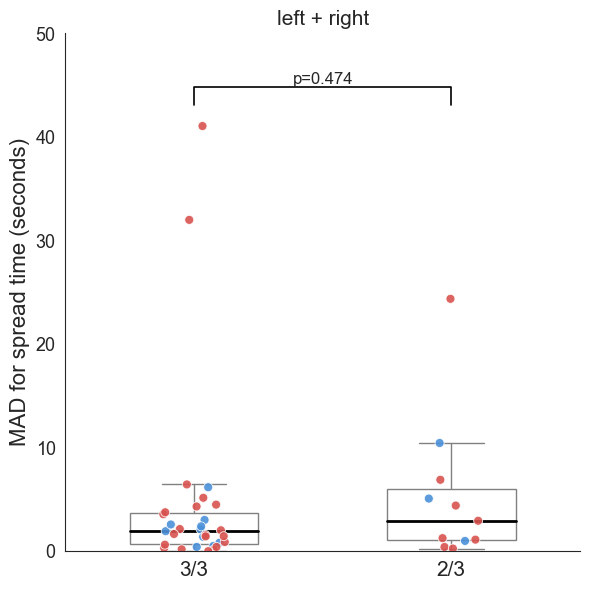

In [10]:
# ==============================================================================
#  Supplementary Figure 6 — spread time MAD, 3/3 vs 2/3 agreement (left + right)
# ==============================================================================
#Fig 3C — onset MAD vs spread MAD (paired Wilcoxon)
"""
plot_mad_panels.py
────────────────────────────────────────────────────────────────────────
MAD figures + statistics from updated_df (output of calculate_channel_agreement).

Included: left / right / bilateral onset only.
Excluded (counts printed): no seizure, complete disagreement (final_MAD=='disagreement'), other.

Figures:
  (1) onset vs spread MAD: one circle per case, gray line joins the same case
       statistics = paired Wilcoxon (onset MAD vs spread MAD)
  (2) spread time MAD: x=[3/3, 2/3] (left+right pooled)   statistics = Mann-Whitney
  ※ (left-only / right-only versions are not drawn)
  ※ figure 2 uses left/right cases with a spread time only (bilateral has no spread time -> excluded)
  ※ 3/3 and 2/3 are restricted to cases with exactly 3 annotators (present=3; same denominator)

Colors: left=red, right=blue, bilateral=yellow.
onset MAD = MAD of onset times of the agreeing annotators (Agreed_Annotators).
spread MAD = updated_df['spread_mad'].
"""

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import wilcoxon, mannwhitneyu

RED, BLUE, YELLOW = '#D9534F', '#4A90D9', '#F0C040'
LAT_COLOR = {'left': RED, 'right': BLUE, 'bilateral': YELLOW}


def _get_laterality(row):
    mg = str(row.get('Majority_Group', '')).strip().lower()
    if 'no seizure' in mg or 'no_seizure' in mg:
        return 'no_seizure'
    if 'left' in mg:
        return 'left'
    if 'right' in mg:
        return 'right'
    if 'bilateral' in mg or 'generalized' in mg:
        return 'bilateral'
    return 'other'


def _agreed_ids(row):
    raw = row.get('Agreed_Annotators')
    if isinstance(raw, (list, np.ndarray)):
        return [int(x) for x in raw if str(x).strip().isdigit()]
    return [int(x) for x in re.findall(r'\d+', str(raw))]


def _n_present(row):
    # The github-spread CSV has no 'Annotator_i' marker columns, so a filled Group_i
    # (= that annotator responded) is used instead.
    n = 0
    for i in range(1, 6):
        g = row.get(f'Group_{i}')
        if g is not None and pd.notna(g):
            n += 1
    return n


def _onset_mad(row, ids):
    vals = []
    for i in ids:
        v = row.get(f'Your_onset_time (s)_{i}')
        s = str(v).lower().strip()
        if s in ('', 'nan', 'none', 'n/a', 'no seizure', 'no_seizure'):
            continue
        try:
            vals.append(float(v))
        except (TypeError, ValueError):
            continue
    if len(vals) < 2:
        return np.nan
    arr = np.array(vals)
    return float(np.median(np.abs(arr - np.median(arr))))


def _to_float(v):
    try:
        f = float(v)
        return f if np.isfinite(f) else np.nan
    except (TypeError, ValueError):
        return np.nan


def _summ(a):
    a = np.asarray(a, float)
    a = a[np.isfinite(a)]
    if a.size == 0:
        return None
    return dict(median=np.median(a), q1=np.percentile(a, 25),
                q3=np.percentile(a, 75), n=a.size)


def _fmt(s):
    return "n/a" if s is None else f"median={s['median']:.2f}s (IQR {s['q1']:.2f}-{s['q3']:.2f}), n={s['n']}"


def _pstr(p):
    if p is None:
        return "n/a"
    return "p<0.001" if p < 0.001 else f"p={p:.3f}"


# ──────────────────────── build data + print exclusions ────────────────────────
def _build(updated_df):
    n_no, n_dis, n_other = 0, 0, 0
    recs = []
    for _, row in updated_df.iterrows():
        lat = _get_laterality(row)
        if lat == 'no_seizure':
            n_no += 1
            continue
        if str(row.get('final_MAD', '')).strip().lower() == 'disagreement':
            n_dis += 1
            continue
        if lat == 'other':
            n_other += 1
            continue
        ids = _agreed_ids(row)
        recs.append(dict(lat=lat, n_agree=len(ids), n_present=_n_present(row),
                         onset_mad=_onset_mad(row, ids),
                         spread_mad=_to_float(row.get('spread_mad', np.nan))))
    print("=== Excluded ===")
    print(f"  no seizure              : {n_no}")
    print(f"  complete disagreement   : {n_dis}")
    if n_other:
        print(f"  other (not L/R/bilateral): {n_other}")
    nl = sum(r['lat'] == 'left' for r in recs)
    nr = sum(r['lat'] == 'right' for r in recs)
    nb = sum(r['lat'] == 'bilateral' for r in recs)
    print(f"=== Included {len(recs)}  (left {nl}, right {nr}, bilateral {nb}) ===")
    return recs


# ──────────────────────── plotting helpers ────────────────────────
def _box_scatter(ax, cats, cat_labels, point_color):
    """cats: list of (values, colors). boxplot + jittered scatter."""
    rng = np.random.default_rng(0)
    data = [np.asarray([v for v in vals if np.isfinite(v)]) for vals, _ in cats]
    ax.boxplot(data, positions=range(len(cats)), widths=0.5, showfliers=False,
               patch_artist=True,
               medianprops=dict(color='black', lw=2),
               boxprops=dict(facecolor='none', edgecolor='gray'),
               whiskerprops=dict(color='gray'), capprops=dict(color='gray'))
    for i, (vals, cols) in enumerate(cats):
        vals = np.asarray(vals, float)
        ok = np.isfinite(vals)
        jx = rng.uniform(-0.12, 0.12, ok.sum())
        ax.scatter(np.full(ok.sum(), i) + jx, vals[ok],
                   c=np.asarray(cols)[ok], s=42, edgecolor='white',
                   linewidth=0.6, zorder=3, alpha=0.9)
    ax.set_xticks(range(len(cats)))
    ax.set_xticklabels(cat_labels, fontsize=15)


def _annot_p(ax, x1, x2, p, y=None):
    """If y is given, draw the bracket at that height (data coordinates) and extend the y-axis above it.
    If y=None, draw it just above the current top of the y-axis."""
    y = ax.get_ylim()[1] if y is None else y
    h = (y - ax.get_ylim()[0]) * 0.04
    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], lw=1.2, c='k')
    ax.text((x1 + x2) / 2, y + h, _pstr(p), ha='center', va='bottom', fontsize=12)
    ax.set_ylim(top=y + h * 4)


def _mwu(a, b):
    a = np.asarray(a, float); a = a[np.isfinite(a)]
    b = np.asarray(b, float); b = b[np.isfinite(b)]
    if len(a) < 1 or len(b) < 1:
        return None
    try:
        return mannwhitneyu(a, b, alternative='two-sided').pvalue
    except ValueError:
        return None


# ──────────────────────── main ────────────────────────
def plot_mad_panels(updated_df, save_prefix=None, include_3v2=True, include_onset_spread=True):
    recs = _build(updated_df)

    # ===== figure 1: onset vs spread MAD (paired Wilcoxon) =====
    # bilateral has no spread time (would look like 0), so figure 1 also uses left/right only.
    lr_recs = [r for r in recs if r['lat'] in ('left', 'right')]
    onset_all = [r['onset_mad'] for r in lr_recs]
    spread_all = [r['spread_mad'] for r in lr_recs]
    paired = [(o, s) for o, s in zip(onset_all, spread_all)
              if np.isfinite(o) and np.isfinite(s)]
    p1 = None
    if len(paired) >= 1:
        po, ps = zip(*paired)
        try:
            p1 = wilcoxon(po, ps).pvalue
        except ValueError:
            p1 = None

    print("\n=== [figure 1] onset vs spread MAD  (left/right only) ===")
    print(f"  onset  MAD: {_fmt(_summ(onset_all))}")
    print(f"  spread MAD: {_fmt(_summ(spread_all))}")
    print(f"  paired n={len(paired)}, Wilcoxon {_pstr(p1)}")

    if include_onset_spread:
        fig1, ax = plt.subplots(figsize=(6.5, 6))
        fig1.patch.set_facecolor('white'); ax.set_facecolor('white')
        rng = np.random.default_rng(1)
        for r in lr_recs:
            jx = rng.uniform(-0.08, 0.08)
            o, s, col = r['onset_mad'], r['spread_mad'], LAT_COLOR[r['lat']]
            if np.isfinite(o) and np.isfinite(s):
                ax.plot([jx, 1 + jx], [o, s], color='gray', lw=0.6, alpha=0.4, zorder=1)
            if np.isfinite(o):
                ax.scatter(jx, o, color=col, s=42, edgecolor='white', lw=0.6, zorder=3)
            if np.isfinite(s):
                ax.scatter(1 + jx, s, color=col, s=42, edgecolor='white', lw=0.6, zorder=3)
        # median line per category
        for xi, vals in [(0, onset_all), (1, spread_all)]:
            sm = _summ(vals)
            if sm:
                ax.plot([xi - 0.25, xi + 0.25], [sm['median']] * 2, color='k', lw=2.5, zorder=4)
        ax.set_xticks([0, 1]); ax.set_xticklabels(['onset', 'spread'], fontsize=15)
        ax.set_ylabel('MAD (seconds)', fontsize=16)
        ax.set_xlim(-0.5, 1.5); ax.set_ylim(bottom=0)
        ax.tick_params(axis='y', labelsize=13)
        for sp in ['top', 'right']:
            ax.spines[sp].set_visible(False)
        _annot_p(ax, 0, 1, p1, y=50)      # [figure 1] p-value bracket placed at y=50
        ax.legend(handles=[Patch(color=RED, label='Left onset'),
                           Patch(color=BLUE, label='Right onset')],
                  loc='upper left', bbox_to_anchor=(1.02, 1.0), frameon=False, fontsize=11)
        fig1.tight_layout()

    # ===== spread time MAD: left/right with present=3 only =====
    sp_recs = [r for r in recs if r['lat'] in ('left', 'right')
               and np.isfinite(r['spread_mad']) and r['n_present'] == 3
               and r['n_agree'] in (2, 3)]

    # check print
    excl = [r for r in recs if r['lat'] in ('left', 'right')
            and np.isfinite(r['spread_mad']) and r['n_present'] != 3]
    pres_dist = {}
    for r in recs:
        if r['lat'] in ('left', 'right') and np.isfinite(r['spread_mad']):
            pres_dist[r['n_present']] = pres_dist.get(r['n_present'], 0) + 1
    print("\n=== [figure 2] spread time MAD cases ===")
    print(f"  number of annotators present in left/right cases with a spread MAD: {dict(sorted(pres_dist.items()))}")
    print(f"  -> present=3 only (3/3 or 2/3 agree). Excluded present!=3: {len(excl)}")
    for side in ('left', 'right'):
        n3 = sum(r['lat'] == side and r['n_agree'] == 3 for r in sp_recs)
        n2 = sum(r['lat'] == side and r['n_agree'] == 2 for r in sp_recs)
        print(f"    {side:5s}: 3/3 = {n3}, 2/3 = {n2}")
    print("  (bilateral has no spread time and is excluded from figure 2)")

    def _spread_fig(subset, title, fname_key):
        v3 = [r['spread_mad'] for r in subset if r['n_agree'] == 3]
        c3 = [LAT_COLOR[r['lat']] for r in subset if r['n_agree'] == 3]
        v2 = [r['spread_mad'] for r in subset if r['n_agree'] == 2]
        c2 = [LAT_COLOR[r['lat']] for r in subset if r['n_agree'] == 2]
        p = _mwu(v3, v2)
        print(f"\n=== [{title}] spread time MAD (3/3 vs 2/3) ===")
        print(f"  3/3: {_fmt(_summ(v3))}")
        print(f"  2/3: {_fmt(_summ(v2))}")
        print(f"  Mann-Whitney {_pstr(p)}")
        fig, ax = plt.subplots(figsize=(6, 6))
        fig.patch.set_facecolor('white'); ax.set_facecolor('white')
        _box_scatter(ax, [(v3, c3), (v2, c2)], ['3/3', '2/3'], None)
        ax.set_ylabel('MAD for spread time (seconds)', fontsize=16)
        ax.set_ylim(bottom=0); ax.tick_params(axis='y', labelsize=13)
        ax.set_title(title, fontsize=15)
        for sp in ['top', 'right']:
            ax.spines[sp].set_visible(False)
        _annot_p(ax, 0, 1, p)
        fig.tight_layout()
        return fig, fname_key

    figs = [(fig1, "onset_spread")] if include_onset_spread else []
    if include_3v2:
        fig2, k2 = _spread_fig(sp_recs, "left + right", "spread_3v2_all")
        figs.append((fig2, k2))

    if save_prefix:
        for fig, key in figs:
            fig.savefig(f"{save_prefix}_{key}.png", dpi=130, bbox_inches='tight')
            plt.close(fig)
    else:
        plt.show()


# Run (Figure 3C = figure 1 only; figure 2 [3/3 vs 2/3] is in supplement_figure.ipynb):
# updated_df = output of the calculate_channel_agreement cell (Figure 3B); recomputing it would redraw that histogram
plot_mad_panels(updated_df, include_onset_spread=False, include_3v2=True)


In [11]:
# ==============================================================================
#  Helper — scalp localization groups (Temporal / Non-Temporal; no figure)
# ==============================================================================
# ══════════════════════════════════════════════════════════════════════════════
#  Attach scalp_localization from Participants_PennEPIID.csv
#  directly to consensus_df by the (Patient_id, seizure_number) key,
#  print the distribution by unique patient + create Temporal vs All-other group labels
#  (the original attached single_loc from deid_with_redcap.csv by Patient_id only;
#   here the seizure-level scalp_localization from the public github-spread CSV is used as is)
# ══════════════════════════════════════════════════════════════════════════════
import pandas as pd
import numpy as np

_PARTICIPANTS_CSV = '../dataset/Participants_PennEPIID.csv'
_part = pd.read_csv(_PARTICIPANTS_CSV)

_loc_map = _part.set_index(['PennEPI', 'seizure_number'])['scalp_localization']
_key_idx = pd.MultiIndex.from_frame(consensus_df[['Patient_id', 'seizure_number']])
consensus_df['single_loc'] = _loc_map.reindex(_key_idx).values

def _loc_group(v):
    if pd.isna(v):
        return 'unknown'
    return 'temporal' if str(v).strip().lower() == 'temporal' else 'non-temporal'

consensus_df['loc_group'] = consensus_df['single_loc'].apply(_loc_group)

# ── distribution print: by unique Patient_id ──────────────────────────────────────
_pid_loc = consensus_df.drop_duplicates('Patient_id').set_index('Patient_id')['single_loc']
print("=== single_loc — by consensus_df patient (unique Patient_id) ===")
print(_pid_loc.fillna('(none/unknown)').value_counts().to_string())
print(f"  total unique patients : {_pid_loc.shape[0]}")

_pid_grp = consensus_df.drop_duplicates('Patient_id')['loc_group']
print("\n=== Temporal vs All-other (unique patients) ===")
print(_pid_grp.value_counts().to_string())

print("\n=== loc_group by seizure (row) ===")
print(consensus_df['loc_group'].value_counts().to_string())

# check unmatched seizures
_unmatched = consensus_df.loc[consensus_df['single_loc'].isna(), 'Patient_id'].unique()
print(f"\nPatients without scalp_localization in Participants_PennEPIID.csv : {len(_unmatched)}")
if len(_unmatched):
    print("  ", sorted(_unmatched.tolist())[:30])


=== single_loc — by consensus_df patient (unique Patient_id) ===
single_loc
temporal          32
multifocal         6
(none/unknown)     5
frontal            5
  total unique patients : 48

=== Temporal vs All-other (unique patients) ===
loc_group
temporal        32
non-temporal    11
unknown          5

=== loc_group by seizure (row) ===
loc_group
temporal        56
non-temporal    15
unknown          8

Patients without scalp_localization in Participants_PennEPIID.csv : 5
   [1, 61, 66, 134, 194]


=== seizures / patients per group ===
  Temporal    : 56 seizures, 32 patients
  Non-Temporal: 23 seizures, 16 patients


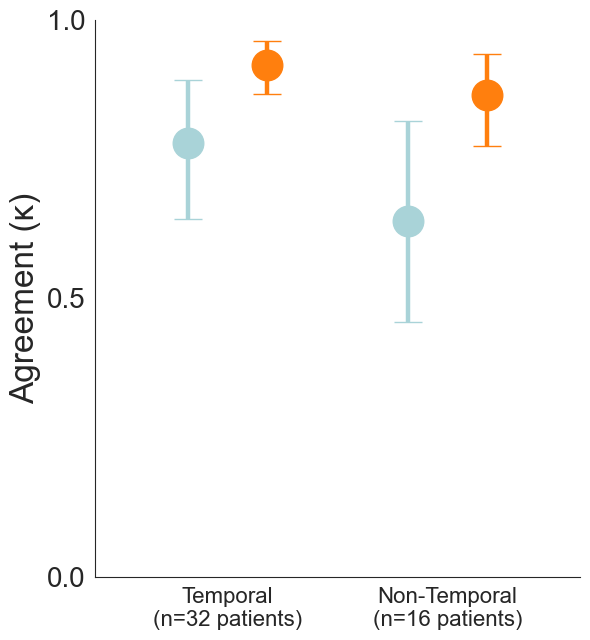

[Onset laterality — Temporal vs Non-Temporal, patient level]
  Temporal     Inter-rater  n= 32 patients  κ = 0.78 [0.64, 0.89]
  Temporal     Consensus    n= 31 patients  κ = 0.92 [0.87, 0.96]
  Non-Temporal Inter-rater  n= 16 patients  κ = 0.64 [0.46, 0.82]
  Non-Temporal Consensus    n= 16 patients  κ = 0.86 [0.77, 0.94]
  Temporal - Non-Temporal  Inter-rater  diff = 0.14 [-0.08, 0.36]  -> ns
  Temporal - Non-Temporal  Consensus    diff = 0.05 [-0.04, 0.17]  -> ns
[whole common inclusion set, regardless of onset agreement, bilateral->Yes] using 55 of 55 seizures
[whole common inclusion set, regardless of onset agreement, bilateral->Yes] using 23 of 23 seizures


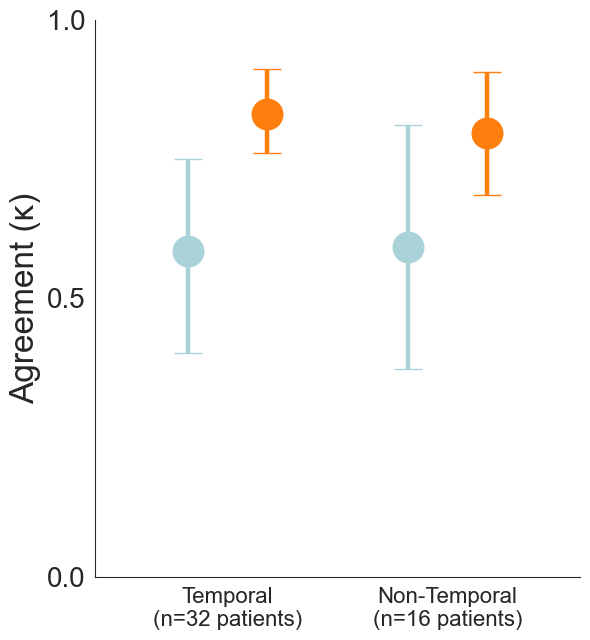

[Contralateral spread — Temporal vs Non-Temporal, patient level]
  Temporal     Inter-rater  n= 32 patients  κ = 0.59 [0.40, 0.75]
  Temporal     Consensus    n= 30 patients  κ = 0.83 [0.76, 0.91]
  Non-Temporal Inter-rater  n= 16 patients  κ = 0.59 [0.37, 0.81]
  Non-Temporal Consensus    n= 16 patients  κ = 0.80 [0.69, 0.91]
  Temporal - Non-Temporal  Inter-rater  diff = -0.01 [-0.29, 0.28]  -> ns
  Temporal - Non-Temporal  Consensus    diff = 0.04 [-0.11, 0.18]  -> ns


In [12]:
# ==============================================================================
#  Supplementary Figure 7 — Temporal vs Non-Temporal, patient level
# ==============================================================================
# ══════════════════════════════════════════════════════════════════════════════
#  Agreement (κ, Gwet's AC1) — Temporal vs Non-Temporal, PATIENT LEVEL
#    - per-seizure AC1 uses a global pe within each group (Temporal / Non-Temporal), as in main
#    - 1 patient = 1 point: mean seizure AC1 per patient within the group -> mean of patient means
#    - 95% CI: 1,000 bootstrap resamples of the patient means
#    - group difference: patient means are bootstrapped within each group; ns if the 95% CI of
#      the difference in means (A − B) includes 0
#    - loc_group is per seizure (scalp_localization), so a patient whose seizures fall in both
#      groups is counted separately in each group with the corresponding seizures
#    - run the "Gwet's AC1 — Overall, PATIENT LEVEL" cell above first (helpers are reused)
# ══════════════════════════════════════════════════════════════════════════════
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

_grp_df = {
    'Temporal':     consensus_df[consensus_df['loc_group'] == 'temporal'].copy(),
    'Non-Temporal': consensus_df[consensus_df['loc_group'] != 'temporal'].copy(),
}
print("=== seizures / patients per group ===")
for g, d in _grp_df.items():
    print(f"  {g:12}: {len(d)} seizures, {d['Patient_id'].nunique()} patients")


def _diff_patient_boot_ci(vals_a, pid_a, vals_b, pid_b, n_bootstrap=1000, seed=42):
    _, pm_a = _patient_means(vals_a, pid_a)
    _, pm_b = _patient_means(vals_b, pid_b)
    if len(pm_a) == 0 or len(pm_b) == 0:
        return (np.nan, np.nan, np.nan)
    rng = np.random.default_rng(seed)
    diffs = [np.mean(rng.choice(pm_a, size=len(pm_a), replace=True))
             - np.mean(rng.choice(pm_b, size=len(pm_b), replace=True)) for _ in range(n_bootstrap)]
    return float(np.mean(pm_a) - np.mean(pm_b)), float(np.percentile(diffs, 2.5)), float(np.percentile(diffs, 97.5))


def _plot_group_comparison_patient(data_by_group, title):
    groups = list(data_by_group)
    pair_gap = 0.18
    fig, ax = plt.subplots(figsize=(6, 6.5))
    cache = {}
    for c, g in enumerate(groups):
        ir_ac1, con_ac1, pid = data_by_group[g]
        ir  = _patient_boot_ci(ir_ac1, pid)
        con = _patient_boot_ci(con_ac1, pid)
        cache[g] = dict(ir=ir, con=con, ir_ac1=ir_ac1, con_ac1=con_ac1, pid=pid)
        ax.errorbar(c - pair_gap, ir[0], yerr=[[ir[0] - ir[1]], [ir[2] - ir[0]]], fmt='o',
                   color=COL_INTER, markersize=22, capsize=10, linewidth=3.2, zorder=3)
        ax.errorbar(c + pair_gap, con[0], yerr=[[con[0] - con[1]], [con[2] - con[0]]], fmt='o',
                   color=COL_CONSENS, markersize=22, capsize=10, linewidth=3.2, zorder=3)

    gA, gB = groups
    d_ir  = _diff_patient_boot_ci(cache[gA]['ir_ac1'],  cache[gA]['pid'], cache[gB]['ir_ac1'],  cache[gB]['pid'])
    d_con = _diff_patient_boot_ci(cache[gA]['con_ac1'], cache[gA]['pid'], cache[gB]['con_ac1'], cache[gB]['pid'])

    ax.set_xticks(range(len(groups)))
    ax.set_xticklabels([f"{g}\n(n={cache[g]['ir'][3]} patients)" for g in groups], fontsize=16)
    ax.set_xlim(-0.6, len(groups) - 0.4)
    ax.set_ylim(0.0, 1.0)
    ax.set_yticks([0.0, 0.5, 1.0])
    ax.set_ylabel("Agreement (κ)", fontsize=24)
    ax.tick_params(axis='y', labelsize=20)
    ax.spines[['top', 'right']].set_visible(False)
    plt.tight_layout()
    plt.show()

    print(f"[{title}, patient level]")
    for g in groups:
        ir_m, ir_lo, ir_hi, n_ir     = cache[g]['ir']
        con_m, con_lo, con_hi, n_con = cache[g]['con']
        print(f"  {g:12} Inter-rater  n={n_ir:3d} patients  κ = {ir_m:.2f} [{ir_lo:.2f}, {ir_hi:.2f}]")
        print(f"  {g:12} Consensus    n={n_con:3d} patients  κ = {con_m:.2f} [{con_lo:.2f}, {con_hi:.2f}]")
    ir_sig  = 'sig' if (d_ir[1] > 0 or d_ir[2] < 0) else 'ns'
    con_sig = 'sig' if (d_con[1] > 0 or d_con[2] < 0) else 'ns'
    print(f"  {gA} - {gB}  Inter-rater  diff = {d_ir[0]:.2f} [{d_ir[1]:.2f}, {d_ir[2]:.2f}]  -> {ir_sig}")
    print(f"  {gA} - {gB}  Consensus    diff = {d_con[0]:.2f} [{d_con[1]:.2f}, {d_con[2]:.2f}]  -> {con_sig}")


# ── (A) Onset laterality ────────────────────────────────────────────────────
lat_by_group = {}
for g, d in _grp_df.items():
    vals_list, majority_list, pid = _build_laterality_lists(d)
    ir_ac1, con_ac1 = _ac1_overall(vals_list, majority_list, ['Left', 'Right', 'Bilateral'])
    lat_by_group[g] = (ir_ac1, con_ac1, pid)
_plot_group_comparison_patient(lat_by_group, "Onset laterality — Temporal vs Non-Temporal")

# ── (B) Contralateral spread (Yes/No) ───────────────────────────────────────
spr_by_group = {}
for g, d in _grp_df.items():
    vals_list, majority_list, pid = _build_spread_lists(d)
    ir_ac1, con_ac1 = _ac1_overall(vals_list, majority_list, ['Yes', 'No'])
    spr_by_group[g] = (ir_ac1, con_ac1, pid)
_plot_group_comparison_patient(spr_by_group, "Contralateral spread — Temporal vs Non-Temporal")


seizures recorded before surgery with an outcome: 47 (30 patients)

Outcome_plot distribution:
Outcome_plot
Poor/Device/No Surgery    38
Good                       9
Name: count, dtype: int64

matched with updated_df (edf_file_name): 47 / 47 (edf_file_name not found: 0)
  of these, seizures with NaN Majority_Group (= no majority laterality among the 3 annotators, not a join failure): 5 -> spread_time values are still used for spread_convert

Patient level (primary) : 30 unique patients (17 with 2+ seizures, 13 with 1 seizure)
Seizure level           : 47 seizures
▶ CONVERT (0-1)  [Patient Level, scalp-before-surgery only]
                            Good  n=7, median=0.050
          Poor/Device/No Surgery  n=23, median=0.093

Mann-Whitney U test: U=71.0, p=0.6583


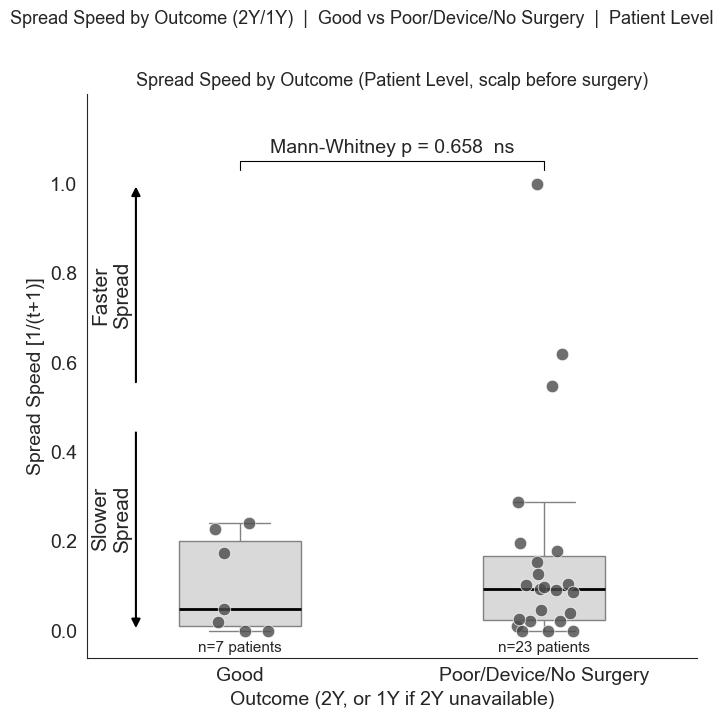

▶ CONVERT (0-1)  [Seizure Level, scalp-before-surgery only]
                            Good  n=9, median=0.050
          Poor/Device/No Surgery  n=38, median=0.078

Mann-Whitney U test: U=158.0, p=0.7345


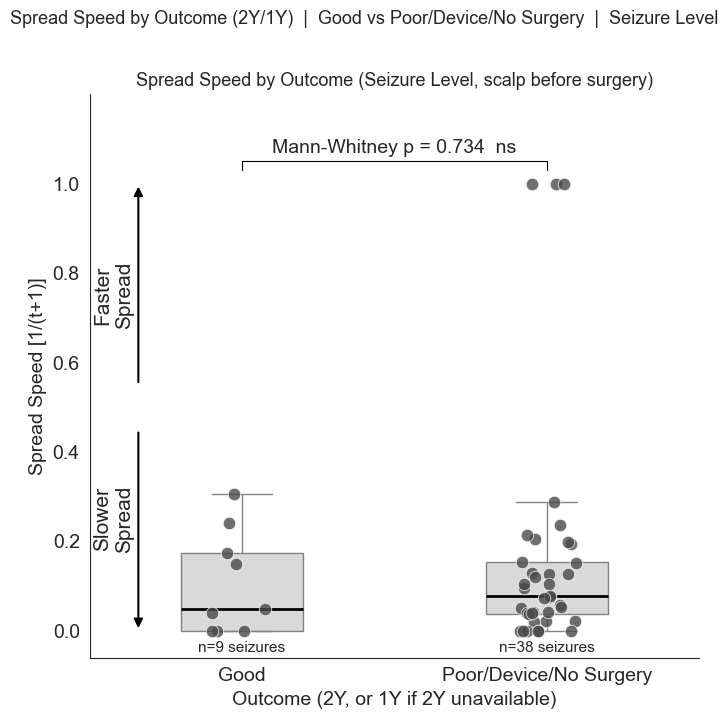

In [13]:
# ==============================================================================
#  Supplementary Figure 8A (patient level) and 8B (seizure level) — spread speed by surgical outcome
# ==============================================================================
# ══════════════════════════════════════════════════════════════════════════════
#  Spread Speed by Surgical Outcome — only the 47 seizures whose scalp EEG was recorded before surgery
#    (rows with a surgical_outcome in Participants_PennEPIID.csv; outcome is provided only for
#     seizures whose scalp EEG admission started before the surgical intervention)
#    - Outcome = surgical_outcome in Participants_PennEPIID.csv (Good = Engel I;
#      Poor/Device/No Surgery = Engel II-IV, device implantation, or no intervention;
#      2-year Engel, or 1-year Engel if the 2-year assessment is unavailable).
#    - spread_time_i / Majority_Group are taken from updated_df (output of
#      calculate_detailed_metrics in cell "#Fig3B"), matched by edf_file_name.
#      (edf_file_name is built from PennEPI/seizure_number — in main_figure.ipynb
#       the 'Patient_id' column of consensus_df/updated_df is actually PennEPI)
#    - spread speed per seizure: consensus onset/spread times across annotators (see section 4)
#    - PRIMARY analysis = Patient level: the outcome is a patient-level variable and 17 of the
#      30 patients contribute 2 seizures, so each patient is reduced to one value (median of
#      their seizures) before the Mann-Whitney test (8A). Seizure level is shown in 8B.
#  ▶ updated_df should exist before running this cell (run the "#Fig3B"
#    (calculate_detailed_metrics) cell first; otherwise it is rebuilt below).
# ══════════════════════════════════════════════════════════════════════════════
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# ── 0) If consensus_df / updated_df do not exist yet (this cell run without the SETUP
#     and "#Fig3B" cells), build them here so the cell is self-contained ──
if "consensus_df" not in globals() or "updated_df" not in globals():
    print("[info] consensus_df/updated_df not found; computing them inside this cell "
          "(running the same logic as the SETUP + '#Fig3B' cells).")

    # ══════════════════════════════════════════════════════════════════════════════
    #  SETUP — build consensus_df from github-spread/Annotation_PennEPIID.csv
    #    (no raw annotator xlsx merging; uses the public CSV that already contains
    #     Group_1~5 / Majority_Group / Agreed_Annotators)
    # ══════════════════════════════════════════════════════════════════════════════
    import pandas as pd
    import numpy as np
    import re
    import ast
    from collections import Counter

    ANNOTATION_CSV = '../dataset/Annotation_PennEPIID.csv'

    consensus_df = pd.read_csv(ANNOTATION_CSV)
    consensus_df = consensus_df.rename(columns={'PennEPI': 'Patient_id'})
    consensus_df['ieeg_file_name'] = consensus_df['edf_file_name']   # alias for compatibility with older code (used only in log output)

    # Group_1~5 / Majority_Group / Agreed_Annotators in the github-spread CSV are a snapshot
    # computed from the channel text at export time, so later edits to Your_onset_channel_i
    # (e.g., restoring midline, removing invalid electrode pairs) are not reflected automatically.
    # -> As in the original live pipeline, Group_i is recomputed every time from the
    #    channel/time text (the CSV's existing Group_i/Majority_Group/Agreed_Annotators are discarded).
    def get_laterality(channel_str):
        if channel_str is None:
            return None
        if isinstance(channel_str, list):
            if len(channel_str) == 0:
                return None
            val_lower = ",".join(map(str, channel_str)).lower()
        else:
            if pd.isna(channel_str) or str(channel_str).lower() in ['n/a', 'none', '', 'nan']:
                return None
            val_lower = str(channel_str).lower()
        if 'diffuse' in val_lower:
            return 'generalized/bilateral'
        nums = re.findall(r'\d+', val_lower)
        if not nums:
            return None
        nums = [int(n) for n in nums]
        has_odd = any(n % 2 != 0 for n in nums)
        has_even = any(n % 2 == 0 for n in nums)
        if has_odd and has_even:
            return 'generalized/bilateral'
        return 'left' if has_odd else 'right'

    def assign_group(row, idx):
        onset_time_val = row.get(f'Your_onset_time (s)_{idx}')
        if pd.isna(onset_time_val):
            return None
        val_str = str(onset_time_val).lower().strip()
        if val_str in ['no seizure', 'no_seizure', 'n/a', 'none']:
            return 'no seizure'
        onset_chan_val = row.get(f'Your_onset_channel_{idx}')
        spread_time_val = row.get(f'Your_contralateral_spread_time (s)_{idx}')
        onset_lat = get_laterality(onset_chan_val)
        is_no_spread = pd.isna(spread_time_val) or str(spread_time_val).lower().strip() in ['n/a', 'none', '', 'nan', 'same']
        if onset_lat == 'generalized/bilateral':
            return 'generalized/bilateral'
        if is_no_spread:
            if onset_lat == 'left':
                return 'only left'
            if onset_lat == 'right':
                return 'only right'
            return 'other'
        if onset_lat == 'left':
            return 'left to spread'
        if onset_lat == 'right':
            return 'right to spread'
        return 'other'

    def get_majority_info_flexible(row):
        groups = [row[f'Group_{i}'] for i in range(1, 6) if row[f'Group_{i}'] is not None]
        if not groups:
            return pd.Series([None, []])
        counts = Counter(groups)
        majority_group, count = counts.most_common(1)[0]
        if count >= 2:
            agreed_annotators = [i for i in range(1, 6) if row[f'Group_{i}'] == majority_group]
            return pd.Series([majority_group, agreed_annotators])
        return pd.Series([None, []])

    for _i in range(1, 6):
        consensus_df[f'Group_{_i}'] = consensus_df.apply(lambda row: assign_group(row, _i), axis=1)
    consensus_df[['Majority_Group', 'Agreed_Annotators']] = consensus_df.apply(get_majority_info_flexible, axis=1)
    # Note: the original notebook merges 'other' (laterality undeterminable, e.g., midline-only response)
    # into 'generalized/bilateral', which would miscount responses with undeterminable laterality
    # as Bilateral. Here 'other' is kept as is
    # (it maps to none of Left/Right/Bilateral in _map_to_group etc., so it is automatically
    #  excluded from the laterality analyses).

    n_resp = consensus_df[[f'Group_{i}' for i in range(1, 6)]].notna().sum(axis=1)
    print(f"[consensus_df] loaded github-spread CSV + recomputed Group: {len(consensus_df)} seizures "
          f"(number-of-raters distribution: {n_resp.value_counts().to_dict()})")


    # ══════════════════════════════════════════════════════════════════════════════
    #  Common seizure inclusion criteria for onset analyses (laterality / channel / onset-time MAD)
    #  (same definition as cell 1 of the original notebook)
    # ══════════════════════════════════════════════════════════════════════════════
    _ONSET_PAIR_RE = re.compile(r'[A-Za-z]{1,4}\d{0,2}\s*-\s*[A-Za-z]{1,4}\d{0,2}')

    def onset_is_no_seizure(val):
        """Whether the onset_time field is 'no seizure' / 'no_seizure'."""
        return "no seizure" in str(val).strip().lower().replace("_", " ")

    def onset_has_channel_pair(val):
        """True if the onset annotation has at least one electrode pair like 'FP1-F9', or is 'diffuse'.
        Midline-only responses such as Fz/Cz/Pz (e.g., 'Cz-Pz') have no digits, so laterality
        cannot be determined; they are skipped -> treated as invalid if there are no digits."""
        if val is None:
            return False
        if isinstance(val, (list, tuple, set)):
            return len(val) > 0
        s = str(val).strip()
        if s == "" or s.lower() in ("nan", "n/a", "none"):
            return False
        if onset_is_no_seizure(s):
            return False
        if "diffuse" in s.lower():
            return True
        if not any(ch.isdigit() for ch in s):
            return False   # midline-only response (Fz/Cz/Pz only) -> skip (invalid)
        return bool(_ONSET_PAIR_RE.search(s))

    def onset_seizure_inclusion(row):
        """
        Seizure inclusion criteria shared by all onset analyses.
          present_ids   : annotators with Group_i filled (= annotated). This dataset has 3 per seizure.
          no_seizure_ids: present annotators whose onset_time is 'no seizure'
          valid_ids     : present annotators who are not no-seizure and have >=1 pair in the onset channel

        Rules:
          1) exclude if present is not exactly 3  (nan = did not annotate)
          2) exclude if 'no seizure' from 2 or more annotators
          3) exclude if fewer than 2 valid_ids (with channel pairs)  (pairwise not computable)
        """
        present_ids = []
        for i in range(1, 6):
            g = row.get(f'Group_{i}', None)
            if g is None:
                continue
            try:
                if pd.isna(g):
                    continue
            except (TypeError, ValueError):
                pass
            if str(g).strip() == "":
                continue
            present_ids.append(i)

        no_seizure_ids = [i for i in present_ids
                          if onset_is_no_seizure(row.get(f'Your_onset_time (s)_{i}', ""))]
        valid_ids = [i for i in present_ids
                     if i not in no_seizure_ids
                     and onset_has_channel_pair(row.get(f'Your_onset_channel_{i}', None))]

        if len(present_ids) != 3:
            inc, reason = False, f'present!=3({len(present_ids)})'
        elif len(no_seizure_ids) >= 2:
            inc, reason = False, 'no_seizure>=2'
        elif len(valid_ids) < 2:
            inc, reason = False, f'valid_channel_raters<2({len(valid_ids)})'
        else:
            inc, reason = True, 'ok'

        return {'included': inc, 'present_ids': present_ids,
                'no_seizure_ids': no_seizure_ids, 'valid_ids': valid_ids, 'reason': reason}

    def ensure_onset_inclusion_cols(df):
        """Return a copy with onset_included / onset_valid_ids added if missing (unchanged if present)."""
        if 'onset_included' in df.columns and 'onset_valid_ids' in df.columns:
            return df
        df = df.copy()
        _oi = df.apply(onset_seizure_inclusion, axis=1)
        df['onset_included']       = _oi.apply(lambda d: d['included'])
        df['onset_valid_ids']      = _oi.apply(lambda d: d['valid_ids'])
        df['onset_no_seizure_ids'] = _oi.apply(lambda d: d['no_seizure_ids'])
        df['onset_incl_reason']    = _oi.apply(lambda d: d['reason'])
        return df

    consensus_df = ensure_onset_inclusion_cols(consensus_df)
    print(f"[onset common inclusion set] included {int(consensus_df['onset_included'].sum())} / {len(consensus_df)}")
    print("  by exclusion reason:")
    print(consensus_df.loc[~consensus_df['onset_included'], 'onset_incl_reason']
          .value_counts().to_string())

    # ══════════════════════════════════════════════════════════════════════════════
    #  Onset laterality mapping helper shared by several cells (first defined in the original notebook's
    #  "(1) Percent Agreement" cell and reused by later cells such as Fleiss/Brennan-Prediger)
    # ══════════════════════════════════════════════════════════════════════════════
    _LEFT, _RIGHT, _BILAT = {'only left', 'left to spread'}, {'only right', 'right to spread'}, {'generalized/bilateral'}
    def _map_to_group(val):
        if val in _LEFT:  return 'Left'
        if val in _RIGHT: return 'Right'
        if val in _BILAT: return 'Bilateral'
        return None

    RATER_IDS = [1, 2, 3, 4, 5]


    #Fig3B
    import pandas as pd
    import numpy as np
    import seaborn as sns
    import matplotlib.pyplot as plt
    from itertools import combinations

    def calculate_detailed_metrics(df):
        # --- [Step 1] compute actual spread time ---
        for i in range(1, 6):
            group_col = f'Group_{i}'
            onset_col = f'Your_onset_time (s)_{i}'
            spread_raw_col = f'Your_contralateral_spread_time (s)_{i}'
        
            # new column
            time_out_col = f'spread_time_{i}'
        
            def get_actual_time(row):
                group_val = str(row[group_col]).lower() if pd.notna(row[group_col]) else ""
            
                # 1. no data or No seizure -> excluded
                if group_val == "" or "no seizure" in group_val:
                    return np.nan
            
                # 2. Generalized / Bilateral -> 0.0 (immediate spread)
                if 'generalized' in group_val or 'bilateral' in group_val:
                    return 0.0
            
                # 3. Only Left / Only Right -> np.inf (no spread)
                if 'only left' in group_val or 'only right' in group_val:
                    return np.inf
            
                # 4. otherwise: try numeric computation (including Diffuse)
                spread_raw = str(row[spread_raw_col]).strip().lower() if pd.notna(row[spread_raw_col]) else ""
            
                if 'diffuse' in spread_raw:
                    return 0.0
            
                onset = pd.to_numeric(row[onset_col], errors='coerce')
                spread_num = pd.to_numeric(spread_raw, errors='coerce')
            
                if pd.notna(spread_num) and pd.notna(onset):
                    return abs(spread_num - onset)
            
                # none of the above (e.g., spread time is empty)
                return np.inf

            df[time_out_col] = df.apply(get_actual_time, axis=1)

        # --- [Step 2] agreement score ---
        interrater_results = []
        consensus_results = []

        for index, row in df.iterrows():
            time_cols = [f'spread_time_{i}' for i in range(1, 5)]
            active_times = [row[c] for c in time_cols if pd.notna(row[c])]

            if len(active_times) < 2:
                interrater_results.append(np.nan)
                consensus_results.append(np.nan)
                continue

            # score transform: 1 / (time + 1)
            # 0.0 (Bilateral) -> score 1.0
            # np.inf (Only side) -> score 0.0
            scores = []
            for t in active_times:
                if t == np.inf:
                    scores.append(0.0)
                else:
                    scores.append(1 / (t + 1))
        
            # Consensus: similarity to the median (1 - distance)
            med_score = np.median(scores)
            consensus_results.append(np.mean([1 - abs(s - med_score) for s in scores]))

            # Inter-rater: mean pairwise similarity
            i_scores = []
            for s1, s2 in combinations(scores, 2):
                i_scores.append(1 - abs(s1 - s2))
            interrater_results.append(np.mean(i_scores))

        plot_df = pd.DataFrame({
            'Metric': ['Inter-rater'] * len(interrater_results) + ['Consensus'] * len(consensus_results),
            'Agreement (0-1)': interrater_results + consensus_results
        }).dropna()
    
        return plot_df, df

    # --- run and check results ---
    final_plot_df, updated_df = calculate_detailed_metrics(consensus_df)

PARTICIPANTS_FINAL_CSV = "../dataset/Participants_PennEPIID.csv"

CAP = 1000
spread_cols = [f"spread_time_{i}" for i in range(1, 6)]

# ── 1) select seizures recorded before surgery (rows with surgical_outcome; 47) and build edf_file_name ──
part = pd.read_csv(PARTICIPANTS_FINAL_CSV)
dc_before = part[part["surgical_outcome"].notna()].copy()
dc_before["edf_file_name"] = dc_before.apply(
    lambda r: f"PennEPI{int(r['PennEPI'])}_seizure{int(r['seizure_number'])}.edf", axis=1
)
print(f"seizures recorded before surgery with an outcome: {len(dc_before)} ({dc_before['PennEPI'].nunique()} patients)")

# ── 2) surgical outcome (precomputed column, see README) ──
dc_before["Outcome_plot"] = dc_before["surgical_outcome"]
print("\nOutcome_plot distribution:")
print(dc_before["Outcome_plot"].value_counts(dropna=False))

# ── 3) match with updated_df (spread_time_i, Majority_Group) by edf_file_name ──
cols_needed = ["edf_file_name", "Patient_id", "Majority_Group"] + spread_cols
cols_needed = [c for c in cols_needed if c in updated_df.columns]
spread_lookup = updated_df[cols_needed].drop_duplicates("edf_file_name").set_index("edf_file_name")

merged = dc_before.merge(
    spread_lookup, left_on="edf_file_name", right_index=True, how="left", suffixes=("", "_spread")
)
n_no_edf_match = (~merged["edf_file_name"].isin(updated_df["edf_file_name"])).sum()
n_no_majority = merged["Majority_Group"].isna().sum()
print(f"\nmatched with updated_df (edf_file_name): {len(merged) - n_no_edf_match} / {len(merged)} "
      f"(edf_file_name not found: {n_no_edf_match})")
print(f"  of these, seizures with NaN Majority_Group (= no majority laterality among the 3 annotators, "
      f"not a join failure): {n_no_majority} -> spread_time values are still used for spread_convert")

# ── 4) spread speed per seizure (consensus across annotators) ──
#   - onset laterality / contralateral spread : annotator majority (>=2 agree), otherwise None
#       (per annotator: bilateral -> spread yes; left/right -> spread yes if a spread time is given)
#   - onset time, spread time : medians of the annotator values, computed separately (>=2 values)
#       (spread time of bilateral/diffuse annotators is filled with their onset time)
#   - spread speed = 1 if consensus laterality is bilateral, 0 if majority says no spread,
#       otherwise t = median(spread time) - median(onset time) -> 1/(1+max(t,0)) (0 if t is missing)
from collections import Counter

def _rater_lat(group_val):
    g = str(group_val).lower()
    if "generalized" in g or "bilateral" in g:
        return "bilateral"
    if g.startswith("left") or g == "only left":
        return "left"
    if g.startswith("right") or g == "only right":
        return "right"
    return None

def _majority(vals):
    vals = [v for v in vals if v is not None and not (isinstance(v, float) and np.isnan(v))]
    if not vals:
        return None
    v, c = Counter(vals).most_common(1)[0]
    return v if c >= 2 else None

def _median2(vals):
    vals = [v for v in vals if pd.notna(v)]
    return np.median(vals) if len(vals) >= 2 else np.nan

def consensus_spread_speed(row):
    lats, spreads, onsets, sp_times = [], [], [], []
    for i in range(1, 6):
        lat = _rater_lat(row.get(f"Group_{i}"))
        sp_t = pd.to_numeric(row.get(f"Your_contralateral_spread_time (s)_{i}"), errors="coerce")
        on_t = pd.to_numeric(row.get(f"Your_onset_time (s)_{i}"), errors="coerce")
        lats.append(lat)
        if lat == "bilateral":
            # bilateral/diffuse annotators: spread time = onset time (immediate spread)
            if pd.isna(sp_t):
                sp_t = on_t
            spreads.append(True)
        elif lat in ("left", "right"):
            spreads.append(pd.notna(sp_t))
        onsets.append(on_t)
        sp_times.append(sp_t)
    lat_c = _majority(lats)
    spread_c = _majority(spreads)
    if lat_c == "bilateral":
        return 1.0
    if spread_c is not True:
        return 0.0
    t = _median2(sp_times) - _median2(onsets)
    if pd.isna(t):
        return 0.0
    return 1.0 / (1.0 + max(t, 0.0))

_speed_lookup = (updated_df.drop_duplicates("edf_file_name")
                 .set_index("edf_file_name")
                 .apply(consensus_spread_speed, axis=1))
merged["spread_convert"] = merged["edf_file_name"].map(_speed_lookup)

group_order = ["Good", "Poor/Device/No Surgery"]
df_plot_seizure = merged.dropna(subset=["spread_convert", "Outcome_plot"]).copy()
df_plot_seizure = df_plot_seizure[df_plot_seizure["Outcome_plot"].isin(group_order)].copy()
df_plot_seizure["Outcome_plot"] = pd.Categorical(df_plot_seizure["Outcome_plot"], categories=group_order, ordered=True)

# Patient level (PRIMARY): one value per patient (PennEPI) = median spread speed of that patient's seizures.
patient_id_col = "PennEPI"
df_plot_patient = (
    df_plot_seizure.groupby(patient_id_col)
    .agg(spread_convert=("spread_convert", "median"), Outcome_plot=("Outcome_plot", "first"))
    .reset_index()
)
df_plot_patient["Outcome_plot"] = pd.Categorical(df_plot_patient["Outcome_plot"], categories=group_order, ordered=True)

_spp = df_plot_seizure.groupby(patient_id_col).size()
print(f"\nPatient level (primary) : {len(df_plot_patient)} unique patients "
      f"({(_spp >= 2).sum()} with 2+ seizures, {(_spp == 1).sum()} with 1 seizure)")
print(f"Seizure level           : {len(df_plot_seizure)} seizures")


# ── 5) plotting function (box + strip + Mann-Whitney) ──
BOX_GRAY = "#D9D9D9"
DOT_GRAY = "#4A4A4A"


def fmt_p(p):
    if p < 0.0001:
        return "p < 0.0001"
    elif p < 0.001:
        return f"p = {p:.4f}"
    else:
        return f"p = {p:.3f}"


def sig_stars(p):
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return "ns"


def plot_spread_by_outcome(df_plot, level_label, unit_label):
    v_good = df_plot.loc[df_plot["Outcome_plot"] == "Good", "spread_convert"].dropna()
    v_poor = df_plot.loc[df_plot["Outcome_plot"] == "Poor/Device/No Surgery", "spread_convert"].dropna()

    u_stat, p_mwu = stats.mannwhitneyu(v_good, v_poor, alternative="two-sided")

    print("=" * 65)
    print(f"▶ CONVERT (0-1)  [{level_label}, scalp-before-surgery only]")
    print(f"  {'Good':>30}  n={len(v_good)}, median={v_good.median():.3f}")
    print(f"  {'Poor/Device/No Surgery':>30}  n={len(v_poor)}, median={v_poor.median():.3f}")
    print(f"\nMann-Whitney U test: U={u_stat:.1f}, p={p_mwu:.4f}")

    fig, ax = plt.subplots(1, 1, figsize=(7, 7))
    value_col = "spread_convert"
    ylabel = "Spread Speed [1/(t+1)]"

    sns.boxplot(
        data=df_plot, x="Outcome_plot", y=value_col,
        order=group_order, color=BOX_GRAY,
        width=0.4, showfliers=False, ax=ax,
        medianprops=dict(color="black", linewidth=2),
    )
    sns.stripplot(
        data=df_plot, x="Outcome_plot", y=value_col,
        order=group_order, color=DOT_GRAY,
        size=9, alpha=0.8, jitter=True,
        edgecolor="white", linewidth=0.6, ax=ax,
    )

    Y_TOP, Y_BOTTOM = 1.2, -0.06
    ax.set_ylim(Y_BOTTOM, Y_TOP)
    ax.set_yticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])

    for i, g in enumerate(group_order):
        n = df_plot[df_plot["Outcome_plot"] == g][value_col].dropna().shape[0]
        ax.text(i, Y_BOTTOM + 0.005, f"n={n} {unit_label}", ha="center", va="bottom", fontsize=11)

    y_line, tip = 1.05, 0.02
    ax.plot([0, 0, 1, 1], [y_line - tip, y_line, y_line, y_line - tip], color="black", linewidth=0.8)
    ax.text(0.5, y_line + 0.01, f"Mann-Whitney {fmt_p(p_mwu)}  {sig_stars(p_mwu)}",
            ha="center", va="bottom", fontsize=14)

    ax.set_xlabel("Outcome (2Y, or 1Y if 2Y unavailable)", fontsize=14)
    ax.set_ylabel(ylabel, fontsize=14)
    ax.set_title(f"Spread Speed by Outcome ({level_label}, scalp before surgery)", fontsize=13)
    ax.set_xlim(-0.5, 1.5)
    ax.tick_params(axis="both", which="major", labelsize=14)
    sns.despine(ax=ax)

    x_arrow, x_text, y_mid = -0.34, -0.42, 0.5
    ax.annotate("", xy=(x_arrow, 1.0), xytext=(x_arrow, y_mid + 0.05), annotation_clip=False,
               arrowprops=dict(arrowstyle="-|>", color="black", linewidth=1.5, mutation_scale=13))
    ax.text(x_text, (y_mid + 1.0) / 2, "Faster\nSpread", rotation=90, ha="center", va="center",
           fontsize=15, clip_on=False)
    ax.annotate("", xy=(x_arrow, 0.0), xytext=(x_arrow, y_mid - 0.05), annotation_clip=False,
               arrowprops=dict(arrowstyle="-|>", color="black", linewidth=1.5, mutation_scale=13))
    ax.text(x_text, (0.0 + y_mid) / 2, "Slower\nSpread", rotation=90, ha="center", va="center",
           fontsize=15, clip_on=False)

    fig.subplots_adjust(left=0.22)
    plt.suptitle(f"Spread Speed by Outcome (2Y/1Y)  |  Good vs Poor/Device/No Surgery  |  {level_label}",
                fontsize=13, y=1.02)
    plt.tight_layout()
    plt.show()


# ── 6) plots: Patient level (8A), then Seizure level (8B) ──
plot_spread_by_outcome(df_plot_patient, "Patient Level", "patients")          # Supplementary Figure 8A
plot_spread_by_outcome(df_plot_seizure, "Seizure Level", "seizures")          # Supplementary Figure 8B
